*Mathematical Foundations of Robotics · Chapter 2 — Spatial Descriptions and Transformations*

# 2.4 Fixed Angles and Euler Angles

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/02-spatial-descriptions-and-transformations/2.4-fixed-angles-and-euler-angles.ipynb)

A rotation matrix has nine entries but only three degrees of freedom. When a person programs a robot on a teach
pendant, or reads an orientation from an inertial sensor, three meaningful numbers — *roll, pitch, yaw* — are far
easier to handle than nine coupled ones. This notebook develops the three-angle descriptions of Craig §2.8: the
**X-Y-Z fixed angles**, the **Z-Y-X** and **Z-Y-Z Euler angles**, and the complete family of 24 conventions. For
each we solve both the *forward* problem (angles to matrix) and the *inverse* problem (matrix to angles), and we
study the one place where three angles inevitably fail — **gimbal lock** — with a rank analysis of the map from angle
rates to angular velocity. Finally we read the tool orientation of a real UR5e and a real Franka Panda from the
MuJoCo simulator, exactly as a teach pendant would display it.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., §2.8 (X-Y-Z fixed angles, Z-Y-X and Z-Y-Z Euler angles) and Appendix B (the 24 angle-set conventions) |
| **Parallel reading** | Lynch & Park Appendix B (Euler angles, roll–pitch–yaw) · Spong et al. Ch. 2 (parameterisations of rotations) · Siciliano et al. §2.4 · Corke *RVC* Ch. 2 |
| **Lectures** | [Prof. G. C. Nandi, Lecture 8 — How to represent orientation?](https://www.youtube.com/watch?v=HmveMBMFTtU) · [Prof. G. C. Nandi, Lecture 9 — Orientation description of a rigid body](https://www.youtube.com/watch?v=MCN5ST40cy8) · [Prof. G. C. Nandi, Lecture 11 — Gimbal lock explained in a practical manner](https://www.youtube.com/watch?v=m50tWpx-t0I) · [Prof. G. C. Nandi, Lecture 12 — Typical solution of Euler angles, type II](https://www.youtube.com/watch?v=wjaFmQKnLOA) · [ThatsEngineering — Fixed and Euler angle representation](https://www.youtube.com/watch?v=uG0P9RX65Ek) · [ThatsEngineering — Euler angles — worked example](https://www.youtube.com/watch?v=8FD1jgb3Df4) |
| **Prerequisites** | [2.2 Mappings and Operators](2.2-mappings-and-operators.ipynb) (fixed versus current axes) and [2.3 Homogeneous Transformations](2.3-homogeneous-transformations.ipynb) |
| **Study time** | about 3 hours, including the exercises |

## Learning objectives

After working through this notebook you should be able to:

1. construct the rotation matrix of **X-Y-Z fixed angles** (roll–pitch–yaw) and of **Z-Y-X** and **Z-Y-Z Euler angles**, and derive each by multiplying elementary rotations in the correct order;
2. prove that three rotations about *fixed* axes equal the same three rotations, in *reverse* order, about *moving* axes;
3. enumerate the **24 angle-set conventions** programmatically, explain why only 12 are genuinely different, and classify them as Tait–Bryan or proper Euler;
4. solve the **inverse problem** with `atan2`, including the second solution and the degenerate (singular) case, and implement a solver valid for any convention;
5. explain **gimbal lock** geometrically and algebraically, by showing that the map from angle rates to angular velocity loses rank, with $\lvert\det E\rvert=\lvert\cos\beta\rvert$ for Tait–Bryan angles;
6. read the tool orientation of a real robot from MuJoCo, convert it to roll–pitch–yaw as a teach pendant would, and use MuJoCo's `eulerseq` correctly (lower case = current axes, upper case = fixed axes).

## Contents

1. [Why three angles?](#1.-Why-three-angles?)
2. [X-Y-Z fixed angles: roll, pitch and yaw](#2.-X-Y-Z-fixed-angles:-roll,-pitch-and-yaw)
3. [Z-Y-X Euler angles and the equivalence theorem](#3.-Z-Y-X-Euler-angles-and-the-equivalence-theorem)
4. [Z-Y-Z Euler angles](#4.-Z-Y-Z-Euler-angles)
5. [The 24 conventions](#5.-The-24-conventions)
6. [The inverse problem](#6.-The-inverse-problem)
7. [Gimbal lock](#7.-Gimbal-lock)
8. [A teach pendant and two real robots](#8.-A-teach-pendant-and-two-real-robots)
9. [Worked examples](#9.-Worked-examples)
10. [Summary, common mistakes and exercises](#10.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

import itertools
import sympy as sp
from scipy.spatial.transform import Rotation as Rot
from rgkit.transforms import (rotx, roty, rotz, skew, unskew, is_rotation, rot_axis_angle, euler_to_rot, rpy_to_rot,
                              rot_to_rpy, euler_zyx_to_rot, rot_to_euler_zyx, euler_zyz_to_rot, rot_to_euler_zyz)

## 1. Why three angles?

Chapter 2.1 showed that a rotation matrix ${}^{A}_{B}R$ is a perfect description of orientation for computation: it
chains by multiplication, it inverts by transposition, and it never fails. It has two disadvantages for people.
First, it is *redundant* — nine numbers constrained by six equations — so a human cannot type one in, and an
algorithm that adjusts it numerically must repair the constraints afterwards. Second, its entries are not
meaningful: it is hard to see from nine direction cosines whether a gripper is tilted by $10^\circ$ or $30^\circ$.
Both difficulties disappear if orientation is specified by **three angles**, which is the minimum number of
parameters ($\dim SO(3) = 3$) and which have a physical meaning: *turn by this much about this axis, then by that
much about that axis, then by that much about a third axis.*

A three-angle description is fixed by three choices:

1. **which axes** the three rotations are about (for example $X$, then $Y$, then $Z$);
2. **fixed or moving axes** — are the axes those of the original frame $\{A\}$ (*fixed angles*), or the axes of the
   frame as it has been turned so far (*Euler angles*)?  Section 2.2 showed that these two readings multiply on
   opposite sides;
3. **the order** of the rotations, because finite rotations do not commute.

Each choice of these three things is a *convention*, and there are 24 of them (Section 5). A number such as
"roll $10^\circ$, pitch $30^\circ$, yaw $45^\circ$" is meaningless until the convention is stated.

> **A warning that governs this whole notebook.** No continuous description of orientation by *three* numbers can be
> free of singular points: the set of orientations $SO(3)$ is topologically different from three-dimensional
> space. Every three-angle convention therefore has orientations at which the description breaks down —
> **gimbal lock** (Section 7) — and every inverse formula has a degenerate case. Redundant descriptions (the
> rotation matrix, and the unit quaternion of Section 2.5) avoid the problem. Angles are for *input, display and
> small corrections*; computation should use matrices or quaternions.

## 2. X-Y-Z fixed angles: roll, pitch and yaw

Start with a frame $\{B\}$ coincident with a reference frame $\{A\}$. Rotate it

1. by $\gamma$ about $\hat X_A$ (**roll**),
2. then by $\beta$ about $\hat Y_A$ (**pitch**),
3. then by $\alpha$ about $\hat Z_A$ (**yaw**).

All three rotations are about the **fixed** axes of $\{A\}$ — the axes do not move with the body. By the
multiplication-order rule of Section 2.2, a rotation about a fixed axis **pre-multiplies**, so the first rotation
ends up on the right and the last on the left:

$$
{}^{A}_{B}R_{XYZ}(\gamma,\beta,\alpha) = R_Z(\alpha)\,R_Y(\beta)\,R_X(\gamma).
$$

(The subscript $XYZ$ records the order in which the rotations are *performed*; the names roll, pitch and yaw come
from aeronautics, with the body's $\hat X$ axis pointing forward, $\hat Y$ to the left and $\hat Z$ up — the usual
mobile-robot convention.) We multiply out in two steps, using the abbreviations
$c_\alpha=\cos\alpha$, $s_\alpha=\sin\alpha$, and so on. The symbolic computation below is done by `sympy`; the
last line checks it against the numerical function of `rgkit.transforms`.

In [2]:
ca, sa, cb, sb, cg, sg = sp.symbols(r"c_\alpha s_\alpha c_\beta s_\beta c_\gamma s_\gamma")
Rz_s = sp.Matrix([[ca, -sa, 0], [sa, ca, 0], [0, 0, 1]])
Ry_s = sp.Matrix([[cb, 0, sb], [0, 1, 0], [-sb, 0, cb]])
Rx_s = sp.Matrix([[1, 0, 0], [0, cg, -sg], [0, sg, cg]])

step1 = Rz_s * Ry_s                                   # first multiply the two left-hand factors ...
R_xyz_s = sp.expand(step1 * Rx_s)                     # ... then multiply by R_X(gamma) on the right
display(Math(r"R_Z(\alpha)R_Y(\beta) = " + sp.latex(step1)))
display(Math(r"{}^{A}_{B}R_{XYZ}(\gamma,\beta,\alpha) = R_Z(\alpha)R_Y(\beta)R_X(\gamma) = " + sp.latex(R_xyz_s)))

g0, b0, a0 = deg(30), deg(40), deg(70)                # a numerical check
subs = {ca: np.cos(a0), sa: np.sin(a0), cb: np.cos(b0), sb: np.sin(b0), cg: np.cos(g0), sg: np.sin(g0)}
print("symbolic matrix agrees with rgkit.rpy_to_rot:",
      np.allclose(np.array(R_xyz_s.subs(subs), dtype=float), rpy_to_rot(g0, b0, a0)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

symbolic matrix agrees with rgkit.rpy_to_rot: True


Two entries of this matrix are worth memorising, because they make the inverse problem easy (Section 6): the
bottom-left entry is $r_{31} = -s_\beta$, and the first column's horizontal part has length
$\sqrt{r_{11}^2+r_{21}^2} = c_\beta$. The figure shows the construction for $(\gamma,\beta,\alpha) =
(30^\circ,40^\circ,70^\circ)$; the dashed black line is the **fixed** axis about which each step turns.

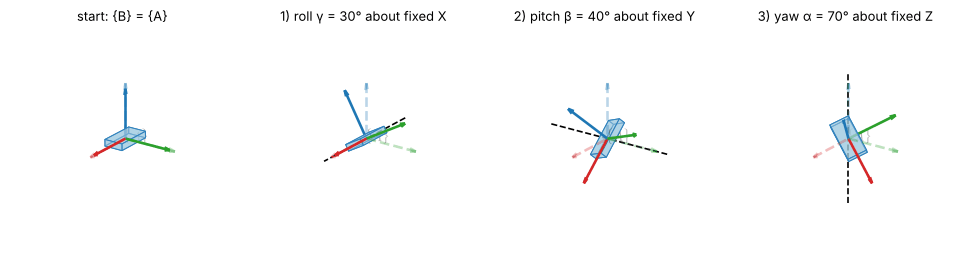

final orientation equals Rz(70°) Ry(40°) Rx(30°): True


In [3]:
ELEM = {"x": rotx, "y": roty, "z": rotz}
UNIT = {"x": np.array([1.0, 0, 0]), "y": np.array([0, 1.0, 0]), "z": np.array([0, 0, 1.0])}

def euler_path(s, angles, order, frame):
    """Orientation after progress s in [0, 3]: the n-th rotation is performed while s runs from n to n+1.

    `order` is the axis sequence in the order the rotations are performed; `frame` is "fixed" or "current".
    Returns (R, axis): the orientation and the world-frame axis of the rotation being performed."""
    R, axis, active = np.eye(3), UNIT[order[0]], int(np.clip(np.ceil(s) - 1, 0, 2))
    for n, (ch, ang) in enumerate(zip(order, angles)):
        step = ELEM[ch](ang * np.clip(s - n, 0.0, 1.0))
        if n == active:
            axis = UNIT[ch] if frame == "fixed" else R @ UNIT[ch]
        R = R @ step if frame == "current" else step @ R
    return R, axis

def draw_state(ax, R, axis=None, title=""):
    ax.cla()
    new_axes3d(ax, lim=1.15, title=title, ticks=False)
    ax.set_axis_off()                                  # no panes or grid: the dashed frame {A} is the reference
    draw_frame(ax, np.eye(3), name="A", alpha=0.3, ls="--", label_axes=False)
    draw_frame(ax, R, length=0.9, label_axes=False)
    draw_box(ax, np.block([[R, np.zeros((3, 1))], [0, 0, 0, 1]]), size=(0.7, 0.35, 0.12))
    if axis is not None:
        ax.plot(*np.outer([-1.2, 1.2], axis).T, "k--", lw=1.4)

rpy_angles = (deg(30), deg(40), deg(70))                       # (roll gamma, pitch beta, yaw alpha)
labels = ["start: {B} = {A}", "1) roll γ = 30° about fixed X", "2) pitch β = 40° about fixed Y", "3) yaw α = 70° about fixed Z"]
fig = plt.figure(figsize=(11.5, 3.2), dpi=85)
for k in range(4):
    ax = fig.add_subplot(1, 4, k + 1, projection="3d")
    R, axis = euler_path(k, rpy_angles, "xyz", "fixed")
    draw_state(ax, R, axis if k > 0 else None, labels[k])
fig.tight_layout(); plt.show()
print("final orientation equals Rz(70°) Ry(40°) Rx(30°):", np.allclose(R, rotz(deg(70)) @ roty(deg(40)) @ rotx(deg(30))))

## 3. Z-Y-X Euler angles and the equivalence theorem

Now perform three rotations about the axes of the **moving** frame instead. Rotate $\{B\}$ (initially $=\{A\}$)

1. by $\alpha$ about $\hat Z_B$;
2. then by $\beta$ about the **new** $\hat Y_B$ (call it $\hat Y_{B'}$);
3. then by $\gamma$ about the **newest** $\hat X_B$ (call it $\hat X_{B''}$).

Every rotation is about a current axis, so each **post-multiplies**: the first rotation is leftmost,

$$
{}^{A}_{B}R_{Z'Y'X'}(\alpha,\beta,\gamma) = R_Z(\alpha)\,R_Y(\beta)\,R_X(\gamma).
$$

This is *exactly the same matrix* as the fixed-angle formula of Section 2. The primes in the subscript denote
rotations about moving axes (Craig's notation), and the product is the same product — only its *reading* differs.

> **Theorem (equivalence of fixed and Euler angles).** Three rotations about the **fixed** axes $a, b, c$ (performed in
> this order, through angles $\theta_1, \theta_2, \theta_3$) give the same orientation as the same three rotations
> about the **moving** axes $c, b, a$ (performed in this order) through $\theta_3, \theta_2, \theta_1$. In
> particular, X-Y-Z fixed angles $(\gamma,\beta,\alpha)$ are the Z-Y-X Euler angles $(\alpha,\beta,\gamma)$.
>
> *Proof.* The fixed-axis sequence gives $R_c(\theta_3)R_b(\theta_2)R_a(\theta_1)$ by pre-multiplication. The
> moving-axis sequence $c, b, a$ with angles $\theta_3,\theta_2,\theta_1$ gives, by post-multiplication,
> $R_c(\theta_3)R_b(\theta_2)R_a(\theta_1)$ — the identical product. $\blacksquare$

The animation performs the two constructions side by side for $(\alpha,\beta,\gamma) = (70^\circ,40^\circ,30^\circ)$.
On the left, the moving-axis rotations Z, then $Y'$, then $X''$; on the right, the fixed-axis rotations X, then Y,
then Z with the angles in reverse order. The intermediate poses differ — the left body first turns about the
vertical, the right body first rolls — but they arrive at the same final orientation. (In the published notebook the
animation appears as a four-frame filmstrip; the full GIF is in the [chapter README](README.md).)

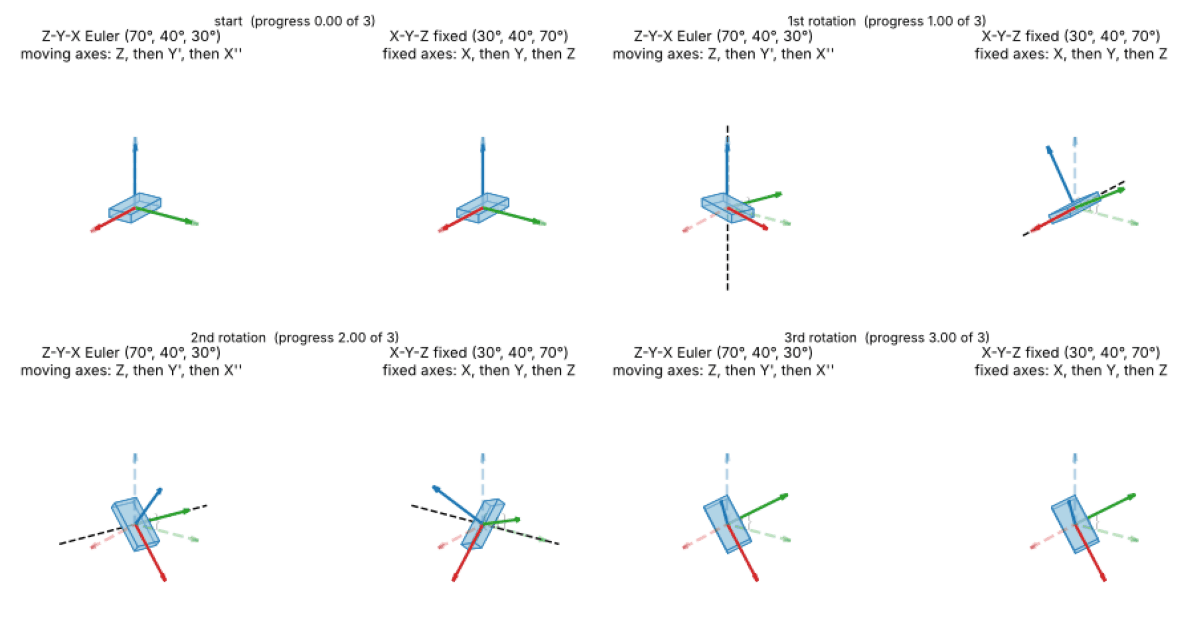

Z-Y-X Euler (70, 40, 30) deg  ==  X-Y-Z fixed (30, 40, 70) deg : True


In [4]:
zyx_angles = (deg(70), deg(40), deg(30))                      # Euler angles (alpha, beta, gamma), moving axes
fig = plt.figure(figsize=(8.6, 4.2), dpi=72)
axL, axR = fig.add_subplot(121, projection="3d"), fig.add_subplot(122, projection="3d")
stage = ["start", "1st rotation", "2nd rotation", "3rd rotation"]

def update(s):
    RL, kL = euler_path(s, zyx_angles, "zyx", "current")
    RR, kR = euler_path(s, zyx_angles[::-1], "xyz", "fixed")
    done = int(np.floor(s + 1e-9))
    draw_state(axL, RL, kL if 0 < s < 3 else None, "Z-Y-X Euler (70°, 40°, 30°)\nmoving axes: Z, then Y', then X''")
    draw_state(axR, RR, kR if 0 < s < 3 else None, "X-Y-Z fixed (30°, 40°, 70°)\nfixed axes: X, then Y, then Z")
    fig.suptitle(f"{stage[min(int(np.ceil(s)), 3)]}  (progress {s:4.2f} of 3)", y=0.99, fontsize=10)

animate(fig, update, np.linspace(0, 3, 37), interval=100, gif="assets/2.4-fixed-equals-euler.gif")
R_euler = euler_zyx_to_rot(*zyx_angles)
R_fixed = rpy_to_rot(zyx_angles[2], zyx_angles[1], zyx_angles[0])
print("Z-Y-X Euler (70, 40, 30) deg  ==  X-Y-Z fixed (30, 40, 70) deg :", np.allclose(R_euler, R_fixed))

**Physical meaning.** For an aircraft or a mobile robot, the Z-Y-X Euler angles are *yaw* (heading, about the
vertical), then *pitch* (nose up or down, about the body's lateral axis) and finally *roll* (bank, about the body's
longitudinal axis). This is the convention in aerospace and in robot middleware; because it is also the X-Y-Z
fixed-angle convention read backwards, one set of formulas serves for both.

### Interactive exploration

Choose the three angles of the X-Y-Z fixed (roll–pitch–yaw) convention. The panel shows the frame, the matrix and
the angles recovered from the matrix by the inverse formulas of Section 6 (they equal the inputs unless the pitch
leaves $[-90^\circ, 90^\circ]$).

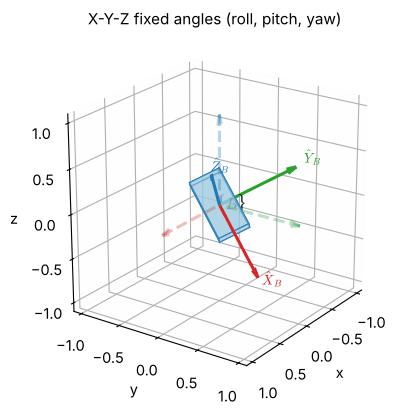

<IPython.core.display.Math object>

recovered (roll, pitch, yaw) = [30. 40. 70.] deg


In [5]:
def explore_rpy(roll=30.0, pitch=40.0, yaw=70.0):
    R = rpy_to_rot(deg(roll), deg(pitch), deg(yaw))
    ax = new_axes3d(lim=1.1, title="X-Y-Z fixed angles (roll, pitch, yaw)", figsize=(4.6, 4.6))
    draw_frame(ax, np.eye(3), name="A", alpha=0.3, ls="--", label_axes=False)
    draw_frame(ax, R, name="B", length=0.9)
    draw_box(ax, np.block([[R, np.zeros((3, 1))], [0, 0, 0, 1]]), size=(0.7, 0.35, 0.12))
    plt.show()
    display(Math(matrix_to_latex(R, 3, r"{}^{A}_{B}R")))
    print("recovered (roll, pitch, yaw) =", np.degrees(rot_to_rpy(R)).round(2), "deg")

interact(explore_rpy,
         roll=widgets.FloatSlider(30, min=-180, max=180, step=5, description="roll γ (°)"),
         pitch=widgets.FloatSlider(40, min=-120, max=120, step=5, description="pitch β (°)"),
         yaw=widgets.FloatSlider(70, min=-180, max=180, step=5, description="yaw α (°)"));

## 4. Z-Y-Z Euler angles

Rotate $\{B\}$ by $\alpha$ about $\hat Z_B$, then by $\beta$ about the new $\hat Y_B$, then by $\gamma$ about the
newest $\hat Z_B$ — an axis *repeated* at the beginning and at the end. Post-multiplying,

$$
{}^{A}_{B}R_{Z'Y'Z'}(\alpha,\beta,\gamma) = R_Z(\alpha)\,R_Y(\beta)\,R_Z(\gamma).
$$

This is a **proper Euler** convention (the first and last axes coincide), in contrast with the **Tait–Bryan**
conventions X-Y-Z, Z-Y-X, … in which all three axes differ. Multiplying out with the same symbols as before:

In [6]:
R_zyz_s = sp.expand(Rz_s * Ry_s * sp.Matrix([[cg, -sg, 0], [sg, cg, 0], [0, 0, 1]]))
display(Math(r"{}^{A}_{B}R_{Z'Y'Z'}(\alpha,\beta,\gamma) = " + sp.latex(R_zyz_s)))
a1, b1, g1 = deg(50), deg(55), deg(40)
subs = {ca: np.cos(a1), sa: np.sin(a1), cb: np.cos(b1), sb: np.sin(b1), cg: np.cos(g1), sg: np.sin(g1)}
print("agrees with rgkit.euler_zyz_to_rot:", np.allclose(np.array(R_zyz_s.subs(subs), dtype=float), euler_zyz_to_rot(a1, b1, g1)))

<IPython.core.display.Math object>

agrees with rgkit.euler_zyz_to_rot: True


**Geometric meaning.** The third column of the matrix is the direction of $\hat Z_B$ in $\{A\}$:
${}^{A}\hat Z_B = (c_\alpha s_\beta,\ s_\alpha s_\beta,\ c_\beta)$. Thus $\alpha$ and $\beta$ are exactly the
**longitude and colatitude** (spherical coordinates) of the tool's $Z$ axis, and $\gamma$ is a **spin about that
axis**. This is why Z-Y-Z is the natural description of a *tool pointing in a direction and then twisted*, and why it
fits a **spherical wrist** — three revolute joints with axes meeting at one point — whose three joint angles
are a roll, a bend and another roll (Chapter 4). The figure shows the three angles for
$(\alpha,\beta,\gamma) = (50^\circ,55^\circ,40^\circ)$.

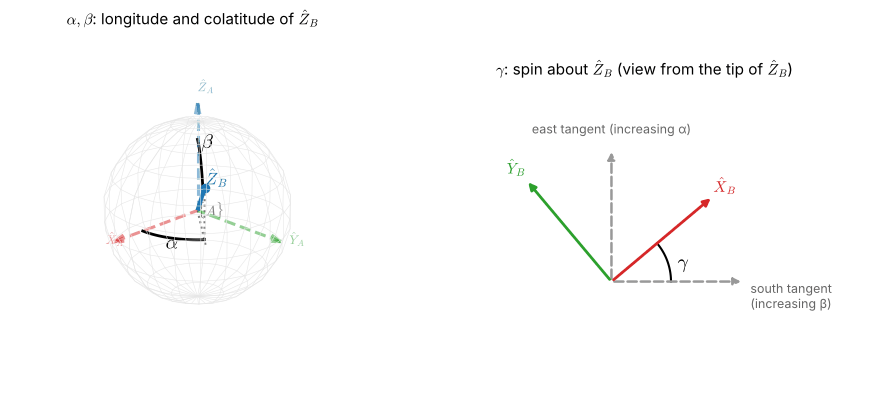

Z_B = [0.5265 0.6275 0.5736]  (cos a sin b, sin a sin b, cos b) = [0.5265 0.6275 0.5736]


In [7]:
def arc3d(ax, centre, u, v, t0, t1, r, **kw):
    """Circular arc of radius r in the plane spanned by the orthonormal vectors u, v."""
    t = np.linspace(t0, t1, 40)
    pts = np.asarray(centre)[:, None] + r * (np.outer(u, np.cos(t)) + np.outer(v, np.sin(t)))
    ax.plot(*pts, **kw)

R = euler_zyz_to_rot(a1, b1, g1)
zB, t_south = R[:, 2], (rotz(a1) @ roty(b1))[:, 0]               # Z_B and the direction of increasing colatitude
e_az = np.array([np.cos(a1), np.sin(a1), 0.0])

fig = plt.figure(figsize=(9.2, 4.2))
ax = fig.add_subplot(121, projection="3d")
new_axes3d(ax, lim=1.15, title=r"$\alpha,\beta$: longitude and colatitude of $\hat Z_B$", azim=45, elev=22, ticks=False)
ax.set_axis_off()
uu, vv = np.mgrid[0:2 * np.pi:24j, 0:np.pi:12j]
ax.plot_wireframe(np.cos(uu) * np.sin(vv), np.sin(uu) * np.sin(vv), np.cos(vv), color="0.9", lw=0.4)
draw_frame(ax, np.eye(3), name="A", alpha=0.5, ls="--", length=1.2, fontsize=9)
draw_vector(ax, [0, 0, 0], zB, color=AXIS_COLORS["z"], lw=3)
ax.scatter(*zB, color=AXIS_COLORS["z"], s=35, depthshade=False)
ax.plot(*np.array([[0, 0, 0], e_az]).T, color="grey", ls=":"); ax.plot(*np.array([zB, [zB[0], zB[1], 0]]).T, color="grey", ls=":")
arc3d(ax, [0, 0, 0], [1, 0, 0], [0, 1, 0], 0, a1, 0.8, color="k", lw=2)                 # alpha: along the equator
arc3d(ax, [0, 0, 0], [0, 0, 1], e_az, 0, b1, 0.8, color="k", lw=2)                      # beta: along the meridian
ax.text(0.95 * np.cos(a1 / 2), 0.95 * np.sin(a1 / 2), -0.06, r"$\alpha$", fontsize=14)
ax.text(*(0.98 * np.array([np.sin(b1 / 2) * np.cos(a1), np.sin(b1 / 2) * np.sin(a1), np.cos(b1 / 2)])), r"$\beta$", fontsize=14)
ax.text(*(1.12 * zB), r"$\hat Z_B$", color=AXIS_COLORS["z"], fontsize=12)

ax2 = fig.add_subplot(122)
ax2.set_title(r"$\gamma$: spin about $\hat Z_B$ (view from the tip of $\hat Z_B$)", fontsize=11)
for d_ in ((1, 0), (0, 1)):                                                                # the two tangent directions at the tip
    ax2.annotate("", xy=d_, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="0.6", lw=1.8, linestyle="--"))
ax2.text(1.05, -0.2, "south tangent\n(increasing β)", color="0.4", fontsize=9)
ax2.text(0.0, 1.12, "east tangent (increasing α)", color="0.4", fontsize=9, ha="center")
draw_frame_2d(ax2, g1, name="B", length=1.0)
arc = np.linspace(0, g1, 30); ax2.plot(0.45 * np.cos(arc), 0.45 * np.sin(arc), "k", lw=1.5); ax2.text(0.5, 0.1, r"$\gamma$", fontsize=14)
ax2.set_xlim(-1.4, 1.9); ax2.set_ylim(-0.5, 1.5); ax2.set_aspect("equal"); ax2.set_axis_off()
fig.tight_layout(); plt.show()
print("Z_B =", zB.round(4), " (cos a sin b, sin a sin b, cos b) =",
      np.round([np.cos(a1) * np.sin(b1), np.sin(a1) * np.sin(b1), np.cos(b1)], 4))

## 5. The 24 conventions

Three rotations about coordinate axes can be chosen in $3\times2\times2 = 12$ ways if no two *consecutive*
rotations may use the same axis (two consecutive rotations about one axis merge into a single rotation, so the third
parameter would be wasted). Each of the 12 sequences can be read as **fixed** axes or as **moving** axes, which gives
$12\times2 = 24$ conventions. By the equivalence theorem of Section 3, however, "fixed $(a,b,c)$" and "moving
$(c,b,a)$" are the same function of the angles, so the 24 conventions collapse into **12 distinct matrix families**.
The cell enumerates the conventions rather than listing them by hand, and verifies the claims numerically.

In [8]:
seqs = ["".join(s) for s in itertools.product("xyz", repeat=3) if s[0] != s[1] and s[1] != s[2]]
conventions = [(s, f) for s in seqs for f in ("current", "fixed")]
print(f"{len(seqs)} axis sequences x 2 readings = {len(conventions)} conventions")

rng = np.random.default_rng(7)
a, b, c = rng.uniform(-np.pi, np.pi, 3)
same = all(np.allclose(euler_to_rot((a, b, c), s, "fixed"), euler_to_rot((c, b, a), s[::-1], "current")) for s in seqs)
print("fixed (s; a,b,c) == moving (reversed s; c,b,a) for every sequence:", same)
mats = {s: euler_to_rot((a, b, c), s, "current") for s in seqs}
print("the 12 moving-axis families are pairwise different:",
      all(not np.allclose(mats[s], mats[t]) for s, t in itertools.combinations(seqs, 2)))

notes = {"zyx": "yaw–pitch–roll (aerospace); same matrix as X-Y-Z fixed angles", "zyz": "Craig §2.8; spherical wrist",
         "zxz": "classical mechanics", "xyz": "same matrix as Z-Y-X fixed angles"}
rows = ["| moving axes (Euler) | equivalent fixed axes | class | note |", "|:--|:--|:--|:--|"]
for s in seqs:
    kind = "Tait–Bryan" if len(set(s)) == 3 else "proper Euler"
    rows.append(f"| {'-'.join(s.upper())} | {'-'.join(s[::-1].upper())} | {kind} | {notes.get(s, '')} |")
display(Markdown("\n".join(rows)))
print("Tait–Bryan:", sum(len(set(s)) == 3 for s in seqs), "  proper Euler:", sum(len(set(s)) == 2 for s in seqs))

12 axis sequences x 2 readings = 24 conventions
fixed (s; a,b,c) == moving (reversed s; c,b,a) for every sequence: True
the 12 moving-axis families are pairwise different: True


| moving axes (Euler) | equivalent fixed axes | class | note |
|:--|:--|:--|:--|
| X-Y-X | X-Y-X | proper Euler |  |
| X-Y-Z | Z-Y-X | Tait–Bryan | same matrix as Z-Y-X fixed angles |
| X-Z-X | X-Z-X | proper Euler |  |
| X-Z-Y | Y-Z-X | Tait–Bryan |  |
| Y-X-Y | Y-X-Y | proper Euler |  |
| Y-X-Z | Z-X-Y | Tait–Bryan |  |
| Y-Z-X | X-Z-Y | Tait–Bryan |  |
| Y-Z-Y | Y-Z-Y | proper Euler |  |
| Z-X-Y | Y-X-Z | Tait–Bryan |  |
| Z-X-Z | Z-X-Z | proper Euler | classical mechanics |
| Z-Y-X | X-Y-Z | Tait–Bryan | yaw–pitch–roll (aerospace); same matrix as X-Y-Z fixed angles |
| Z-Y-Z | Z-Y-Z | proper Euler | Craig §2.8; spherical wrist |

Tait–Bryan: 6   proper Euler: 6


**Which one is in use?** There is no universal answer, which is why a convention must always be stated. Libraries
disagree even about the *letters*. MuJoCo's `eulerseq` attribute uses **lower-case letters for moving (current)
axes and upper-case letters for fixed axes**, and lists the axes in the order in which the rotations are performed;
SciPy's `Rotation.from_euler` uses the **opposite** letter-case rule (lower case = fixed, "extrinsic"; upper case =
moving, "intrinsic"), with the same order. The next cell checks both libraries against our `euler_to_rot` for **all 24
conventions** and random angles.

In [9]:
from rgkit import mujoco_utils as mju          # selects an OpenGL backend; import it before mujoco
import mujoco
rng = np.random.default_rng(3)
n_ok_mj = n_ok_sp = 0
for seq, frame in conventions:
    ang = rng.uniform(-np.pi, np.pi, 3)
    ours = euler_to_rot(ang, seq, frame)
    letters_mj = seq if frame == "current" else seq.upper()                       # MuJoCo: lower = current, UPPER = fixed
    xml = (f'<mujoco><compiler angle="radian" eulerseq="{letters_mj}"/><worldbody>'
           f'<body name="b" euler="{ang[0]} {ang[1]} {ang[2]}"/></worldbody></mujoco>')
    m = mujoco.MjModel.from_xml_string(xml); d = mujoco.MjData(m); mujoco.mj_forward(m, d)
    n_ok_mj += np.allclose(d.body("b").xmat.reshape(3, 3), ours, atol=1e-12)
    letters_sp = seq.upper() if frame == "current" else seq                      # SciPy: UPPER = intrinsic (current)
    n_ok_sp += np.allclose(Rot.from_euler(letters_sp, ang).as_matrix(), ours, atol=1e-12)
print(f"MuJoCo eulerseq reproduces euler_to_rot for {n_ok_mj}/24 conventions;  SciPy for {n_ok_sp}/24.")
print("Same letters, opposite meaning: MuJoCo 'xyz' (current) equals SciPy 'XYZ':",
      np.allclose(euler_to_rot((0.3, -0.5, 1.1), "xyz", "current"), Rot.from_euler("XYZ", (0.3, -0.5, 1.1)).as_matrix()))

MuJoCo eulerseq reproduces euler_to_rot for 24/24 conventions;  SciPy for 24/24.
Same letters, opposite meaning: MuJoCo 'xyz' (current) equals SciPy 'XYZ': True


## 6. The inverse problem

**Forward** problems are easy: multiply three matrices. The **inverse** problem — given a numerical rotation matrix
$R = [r_{ij}]$, find the angles — is solved by comparing the numerical matrix with the symbolic one entry by entry
and choosing entries that isolate one angle at a time. The key is to use `atan2`, which keeps both signs.

### Inverse of X-Y-Z fixed angles (Craig eq. 2.66)

From Section 2, $r_{31} = -s_\beta$ and $r_{11}^2 + r_{21}^2 = c_\alpha^2c_\beta^2 + s_\alpha^2c_\beta^2 = c_\beta^2$, hence
$c_\beta = \pm\sqrt{r_{11}^2+r_{21}^2}$. Taking the **positive** root ($-90^\circ \le \beta \le 90^\circ$),

$$
\beta = \operatorname{atan2}\!\big(-r_{31},\ \sqrt{r_{11}^2+r_{21}^2}\big),\qquad
\alpha = \operatorname{atan2}\!\Big(\frac{r_{21}}{c_\beta},\ \frac{r_{11}}{c_\beta}\Big),\qquad
\gamma = \operatorname{atan2}\!\Big(\frac{r_{32}}{c_\beta},\ \frac{r_{33}}{c_\beta}\Big).
$$

Dividing by $c_\beta>0$ changes nothing numerically but makes the sign bookkeeping explicit, which is needed for the
second solution.

**The second solution.** Taking the *negative* root, $c_\beta = -\sqrt{r_{11}^2+r_{21}^2}$, gives
$\beta' = 180^\circ - \beta$, $\alpha' = \alpha + 180^\circ$, $\gamma' = \gamma + 180^\circ$, which produces the
*same matrix*. Every orientation therefore has **two** X-Y-Z descriptions; by convention one reports the solution
with $\lvert\beta\rvert \le 90^\circ$.

**The degenerate case.** If $c_\beta = 0$ ($\beta = \pm 90^\circ$), then $r_{11}=r_{21}=r_{32}=r_{33}=0$ and the
formulas for $\alpha$ and $\gamma$ become $\operatorname{atan2}(0,0)$. Only the *difference* $\gamma-\alpha$ (for
$\beta = +90^\circ$) or the *sum* $\gamma+\alpha$ (for $\beta=-90^\circ$) can be determined (Section 7).
The convention (Craig eqs. 2.67–2.68) is to set $\alpha = 0$ and
$$
\beta=+90^\circ:\ \gamma=\operatorname{atan2}(r_{12},r_{22}),\qquad
\beta=-90^\circ:\ \gamma=-\operatorname{atan2}(r_{12},r_{22}).
$$

### Inverse of Z-Y-Z Euler angles (Craig eq. 2.74)

From the matrix of Section 4: $r_{33} = c_\beta$ and $r_{31}^2 + r_{32}^2 = s_\beta^2$. Taking $s_\beta > 0$
($0<\beta<180^\circ$),

$$
\beta = \operatorname{atan2}\!\big(\sqrt{r_{31}^2+r_{32}^2},\ r_{33}\big),\qquad
\alpha = \operatorname{atan2}\!\Big(\frac{r_{23}}{s_\beta},\ \frac{r_{13}}{s_\beta}\Big),\qquad
\gamma = \operatorname{atan2}\!\Big(\frac{r_{32}}{s_\beta},\ \frac{-r_{31}}{s_\beta}\Big),
$$

with second solution $(\alpha+180^\circ,\ -\beta,\ \gamma+180^\circ)$. If $s_\beta = 0$ the matrix is $R_Z(\alpha+\gamma)$
(for $\beta=0$) or a rotation depending on $\alpha-\gamma$ only (for $\beta=180^\circ$); with the convention $\alpha=0$:
$\gamma = \operatorname{atan2}(-r_{12}, r_{11})$ for $\beta = 0$ and $\gamma = \operatorname{atan2}(r_{12}, -r_{11})$ for $\beta=180^\circ$.

The functions below implement these formulas **from scratch**, return both solutions, and are tested on 2000 random
rotations against the reference implementation of `rgkit`.

In [10]:
wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi        # map an angle to (-pi, pi]

def rpy_from_R(R, tol=1e-9):
    """X-Y-Z fixed angles: (principal, alternate) = ((roll, pitch, yaw), (roll', pitch', yaw')).
    At gimbal lock (cos(pitch) = 0) the yaw is set to 0 and `alternate` is None."""
    c = np.hypot(R[0, 0], R[1, 0])                       # = |cos(beta)|
    beta = np.arctan2(-R[2, 0], c)
    if c < tol:                                          # degenerate: only gamma -/+ alpha is defined
        gamma = np.sign(beta) * np.arctan2(R[0, 1], R[1, 1])
        return (gamma, beta, 0.0), None
    alpha, gamma = np.arctan2(R[1, 0] / c, R[0, 0] / c), np.arctan2(R[2, 1] / c, R[2, 2] / c)
    alt = (wrap(gamma + np.pi), wrap(np.pi - beta), wrap(alpha + np.pi))
    return (gamma, beta, alpha), alt

def zyz_from_R(R, tol=1e-9):
    """Z-Y-Z Euler angles: (principal, alternate) = ((alpha, beta, gamma), ...) with beta in [0, pi]."""
    s = np.hypot(R[2, 0], R[2, 1])                       # = sin(beta) >= 0
    beta = np.arctan2(s, R[2, 2])
    if s < tol:                                          # beta = 0 or pi: only alpha +/- gamma is defined
        gamma = np.arctan2(-R[0, 1], R[0, 0]) if R[2, 2] > 0 else np.arctan2(R[0, 1], -R[0, 0])
        return (0.0, beta, gamma), None
    alpha, gamma = np.arctan2(R[1, 2] / s, R[0, 2] / s), np.arctan2(R[2, 1] / s, -R[2, 0] / s)
    return (alpha, beta, gamma), (wrap(alpha + np.pi), -beta, wrap(gamma + np.pi))

Rs = Rot.random(2000, random_state=1).as_matrix()
err_rpy = err_alt = err_zyz = err_ref = 0.0
for R in Rs:
    (g, b, a), alt = rpy_from_R(R)
    err_rpy = max(err_rpy, abs(rpy_to_rot(g, b, a) - R).max())
    err_alt = max(err_alt, abs(rpy_to_rot(alt[0], alt[1], alt[2]) - R).max())
    err_ref = max(err_ref, abs(np.array(rot_to_rpy(R)) - np.array([g, b, a])).max())
    (a2, b2, g2), alt2 = zyz_from_R(R)
    err_zyz = max(err_zyz, abs(euler_zyz_to_rot(a2, b2, g2) - R).max(), abs(euler_zyz_to_rot(*alt2) - R).max())
print(f"RPY: round-trip error {err_rpy:.1e}, alternate solution error {err_alt:.1e}, difference from rgkit {err_ref:.1e}")
print(f"ZYZ: round-trip error of principal and alternate solutions {err_zyz:.1e}")
print("Both solutions of rpy_from_R(Rz(110°)Ry(-35°)Rx(20°)):",
      np.degrees(rpy_from_R(rpy_to_rot(deg(20), deg(-35), deg(110)))[0]).round(2), "and",
      np.degrees(rpy_from_R(rpy_to_rot(deg(20), deg(-35), deg(110)))[1]).round(2))

RPY: round-trip error 6.2e-15, alternate solution error 5.7e-15, difference from rgkit 4.4e-16
ZYZ: round-trip error of principal and alternate solutions 1.9e-15
Both solutions of rpy_from_R(Rz(110°)Ry(-35°)Rx(20°)): [ 20. -35. 110.] and [-160. -145.  -70.]


### One solver for every convention

Section 5 shows that there are 24 conventions, and a robot controller may use any of them. It would be tedious to
derive 12 sets of formulas, and it is unnecessary: **every convention reduces to one of the two cases above by
relabelling the axes.**

* A fixed-axes reading of $(a,b,c)$ is the moving-axes reading of the reversed sequence with the angles reversed
  (Section 3), so it suffices to treat moving axes.
* For a moving-axis sequence $(i,j,k)$, choose the permutation $\sigma$ of the axes with $\sigma(i)=Z$, $\sigma(j)=Y$ and
  $\sigma(\text{third axis})=X$. Let $P$ be the permutation matrix with $P\hat e_m = \hat e_{\sigma(m)}$. Conjugation
  by $P$ relabels the axes: $P\,R_m(\theta)\,P^{\mathsf T} = R_{\sigma(m)}(s\,\theta)$, where $s=\det P=\pm1$ (an odd
  permutation reverses the sense of rotation). Hence $PRP^{\mathsf T}$ has the canonical form $R_Z(s a)R_Y(s b)R_X(s c)$
  (Tait–Bryan, $k\ne i$) or $R_Z(s a)R_Y(s b)R_Z(s c)$ (proper Euler, $k=i$), which the formulas above solve.
* For proper Euler angles, a negative $b$ is replaced by $(a+180^\circ,-b,c+180^\circ)$ to restore $b\in[0,\pi]$.

The result is a dozen lines, and it can be tested against SciPy for all 24 conventions.

In [11]:
AX = {"x": 0, "y": 1, "z": 2}

def _canon_tait_bryan(R):                                  # R = Rz(a) Ry(b) Rx(c), |b| <= pi/2, a = 0 at lock
    return np.array(rpy_from_R(R)[0])[[2, 1, 0]]

def _canon_proper(R):                                      # R = Rz(a) Ry(b) Rz(c), 0 <= b <= pi, a = 0 at lock
    return np.array(zyz_from_R(R)[0])

def euler_from_R(R, order="zyx", frame="current"):
    """Principal angles (in the order the rotations are performed) of ANY of the 24 conventions."""
    order = order.lower()
    if frame == "fixed":                                   # fixed (a,b,c) = moving (reversed axes; reversed angles)
        return euler_from_R(R, order[::-1], "current")[::-1]
    i, j, k = (AX[ch] for ch in order)
    sigma = np.empty(3, int); sigma[i], sigma[j], sigma[3 - i - j] = 2, 1, 0
    P = np.zeros((3, 3)); P[sigma, np.arange(3)] = 1.0     # P e_m = e_sigma(m)
    s = np.linalg.det(P)
    proper = (i == k)
    a, b, c = s * (_canon_proper if proper else _canon_tait_bryan)(P @ R @ P.T)
    if proper and b < -1e-12:                              # restore b in [0, pi]
        a, b, c = (a, np.pi, c) if abs(b + np.pi) < 1e-9 else (a + np.pi, -b, c + np.pi)
    return np.array([wrap(a), b, wrap(c)])

rng = np.random.default_rng(0)
worst_rt = worst_sp = 0.0
for seq, frame in conventions:
    for _ in range(100):
        R = Rot.random(random_state=int(rng.integers(1e9))).as_matrix()
        ang = euler_from_R(R, seq, frame)
        worst_rt = max(worst_rt, abs(euler_to_rot(ang, seq, frame) - R).max())                      # round trip
        sp_ang = Rot.from_matrix(R).as_euler(seq.upper() if frame == "current" else seq)            # SciPy's answer
        worst_sp = max(worst_sp, abs(wrap(sp_ang - ang)).max())
print(f"all 24 conventions: worst round-trip error {worst_rt:.1e},  worst difference from SciPy's angles {worst_sp:.1e} rad")

all 24 conventions: worst round-trip error 1.5e-15,  worst difference from SciPy's angles 5.8e-15 rad


**Ill-conditioning near the singularity.** The inverse formulas are exact, but they are *numerically unstable* when
$c_\beta$ is small: $\alpha$ and $\gamma$ are computed from ratios $r_{21}/c_\beta$, so rounding errors and sensor
noise in $r_{ij}$ are amplified by $1/c_\beta$. The experiment perturbs a rotation with pitch $89.99^\circ$ by
a rotation of only $10^{-5}$ rad: the orientation barely changes, yet the roll and yaw returned by the inverse
formulas change by tens of degrees. Only their difference, which is what the orientation really depends on, is stable.

In [12]:
R_a = rpy_to_rot(deg(20), deg(89.99), deg(30))
R_b = rotx(1e-5) @ R_a                                                  # a tiny rotation of 1e-5 rad
for name, R in (("R_a", R_a), ("R_b", R_b)):
    g, b, a = np.degrees(rpy_from_R(R)[0])
    print(f"{name}: roll {g:8.3f}°  pitch {b:7.3f}°  yaw {a:8.3f}°   roll - yaw = {g - a:8.3f}°")
print("angle between the two orientations:", np.degrees(np.arccos((np.trace(R_a.T @ R_b) - 1) / 2)).round(6), "deg  (= 1e-5 rad =", np.degrees(1e-5).round(6), "deg)")

R_a: roll   20.000°  pitch  89.990°  yaw   30.000°   roll - yaw =  -10.000°
R_b: roll   22.762°  pitch  89.990°  yaw   32.762°   roll - yaw =  -10.000°
angle between the two orientations: 0.000573 deg  (= 1e-5 rad = 0.000573 deg)


## 7. Gimbal lock

### 7.1 The physical picture

Imagine the three angles realised by three nested rings (gimbals), as in a gyroscopic navigation platform. For
Z-Y-X angles the **outer ring** turns about the fixed vertical axis ($\alpha$), the **middle ring** is mounted in it
and turns about $\hat Y'$ ($\beta$), and the **inner body** is mounted in the middle ring and turns about its own
$\hat X''$ ($\gamma$). The three axes are normally independent, so any small rotation of the body can be produced by
moving some ring. When the middle ring turns by $\beta=90^\circ$, however, the body's $\hat X''$ axis points along the
vertical axis: the outer and the inner rotation axes **coincide**, the outer and middle rings become coplanar, and
turning either of them produces the same motion. A rotation about the axis *perpendicular* to both ($\hat X'$, in the
horizontal plane) is now impossible without a violent reorientation of the rings. One degree of freedom has been
lost: this is **gimbal lock**. (The navigation platform of the Apollo spacecraft had three gimbals and had to be kept
away from this configuration.) The animation moves the middle ring from $0^\circ$ to $90^\circ$; the right panel
shows $\lvert\cos\beta\rvert$, the quantity that measures how far the rings are from locking (Section 7.3).

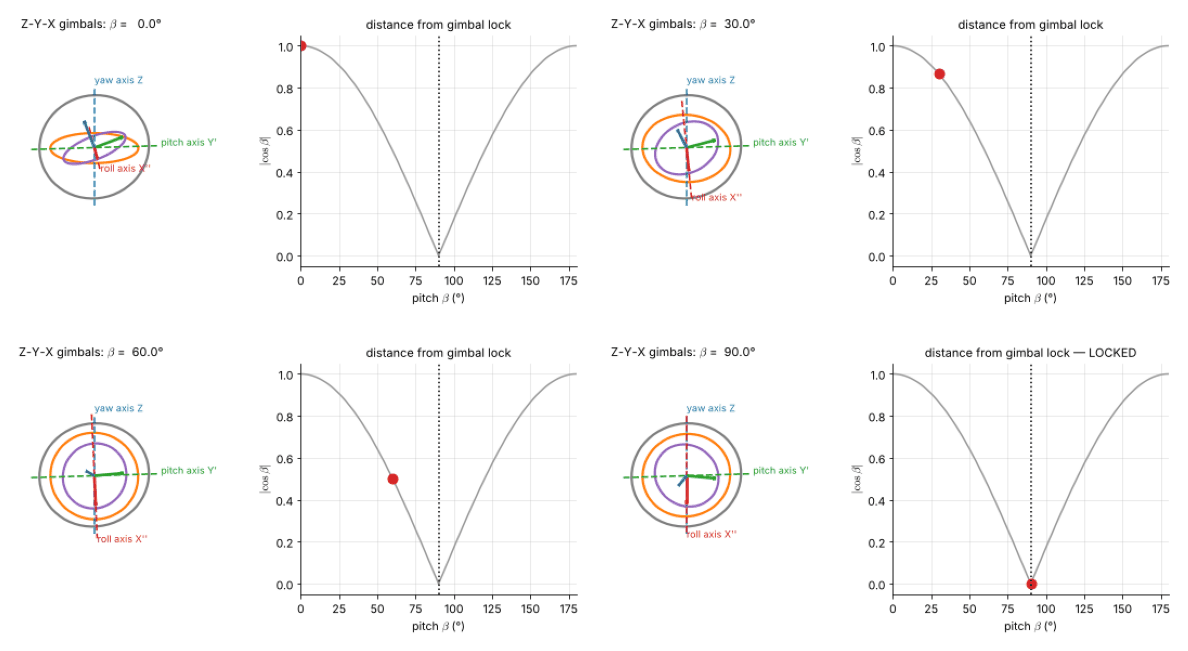

In [13]:
def circle(centre, u, v, r, n=60):
    t = np.linspace(0, 2 * np.pi, n)
    return np.asarray(centre)[:, None] + r * (np.outer(u, np.cos(t)) + np.outer(v, np.sin(t)))

def draw_gimbal(ax, alpha, beta, gamma):
    ax.cla()
    new_axes3d(ax, lim=1.25, ticks=False, azim=35, elev=20)
    ax.set_axis_off()
    R1 = rotz(alpha); R2 = R1 @ roty(beta); R3 = R2 @ rotx(gamma)
    ez, y1, x2 = UNIT["z"], R1[:, 1], R2[:, 0]
    o = np.zeros(3)
    ax.plot(*circle(o, ez, y1, 1.0), color="#7f7f7f", lw=2.2)                  # outer ring: bearings Z and Y'
    ax.plot(*circle(o, y1, x2, 0.8), color="#ff7f0e", lw=2.2)                  # middle ring: bearings Y' and X''
    ax.plot(*circle(o, R3[:, 0], R3[:, 1], 0.6), color="#9467bd", lw=2.2)      # inner body: bearing X''
    for vec, col, lab in ((ez, AXIS_COLORS["z"], "yaw axis Z"), (y1, AXIS_COLORS["y"], "pitch axis Y'"),
                          (x2, AXIS_COLORS["x"], "roll axis X''")):
        ax.plot(*np.outer([-1.15, 1.15], vec).T, color=col, lw=1.6, ls="--")
        ax.text(*(1.22 * vec), lab, color=col, fontsize=9)
    draw_frame(ax, R3, length=0.55, label_axes=False, lw=2.6)

fig = plt.figure(figsize=(8.6, 4.0), dpi=72)
gs = fig.add_gridspec(1, 2, width_ratios=[1.25, 1], left=0.0, right=0.98, bottom=0.16, top=0.9, wspace=0.12)
axG = fig.add_subplot(gs[0], projection="3d"); axC = fig.add_subplot(gs[1])
bb = np.linspace(0, np.pi, 181)

def update(beta):
    draw_gimbal(axG, deg(40), beta, deg(20))
    axG.set_title(rf"Z-Y-X gimbals: $\beta$ = {np.degrees(beta):5.1f}°", fontsize=11)
    axC.cla()
    axC.plot(np.degrees(bb), np.abs(np.cos(bb)), color="0.6"); axC.plot(np.degrees(beta), abs(np.cos(beta)), "o", color="#d62728", ms=9)
    axC.set_xlabel(r"pitch $\beta$ (°)"); axC.set_ylabel(r"$|\cos\beta|$"); axC.set_xlim(0, 180); axC.set_ylim(-0.05, 1.05)
    axC.axvline(90, color="k", ls=":"); axC.set_title("distance from gimbal lock" + (" — LOCKED" if abs(np.cos(beta)) < 1e-6 else ""), fontsize=11)

animate(fig, update, deg(90) * np.linspace(0, 1, 37), interval=100, gif="assets/2.4-gimbal-lock.gif")

### 7.2 The algebra: the matrix depends on one angle only

Put $\beta=90^\circ$, i.e. $c_\beta=0$, $s_\beta=1$, in the X-Y-Z matrix of Section 2. Using
$\sin(\gamma-\alpha) = s_\gamma c_\alpha - c_\gamma s_\alpha$ and $\cos(\gamma-\alpha) = c_\gamma c_\alpha + s_\gamma s_\alpha$,

$$
R = \begin{bmatrix} 0 & \sin(\gamma-\alpha) & \cos(\gamma-\alpha)\\ 0 & \cos(\gamma-\alpha) & -\sin(\gamma-\alpha)\\ -1 & 0 & 0\end{bmatrix}.
$$

The matrix depends on $\gamma-\alpha$ only: adding the same amount to $\alpha$ and $\gamma$ changes nothing. Three
numbers now describe only two degrees of freedom, and the inverse problem has infinitely many solutions.

In [14]:
Rlock = R_xyz_s.subs({cb: 0, sb: 1})
display(Math(r"R\big|_{\beta=90^\circ} = " + sp.latex(Rlock)))
R_1 = rpy_to_rot(deg(65), deg(90), deg(15)); R_2 = rpy_to_rot(deg(95), deg(90), deg(45)); R_3 = rpy_to_rot(deg(-40), deg(90), deg(-90))
print("(roll, yaw) = (65°, 15°), (95°, 45°) and (-40°, -90°) all have roll - yaw = 50°; same matrix:",
      np.allclose(R_1, R_2) and np.allclose(R_1, R_3))
print("the matrix equals the pattern above with gamma - alpha = 50°:",
      np.allclose(R_1, [[0, np.sin(deg(50)), np.cos(deg(50))], [0, np.cos(deg(50)), -np.sin(deg(50))], [-1, 0, 0]]))

<IPython.core.display.Math object>

(roll, yaw) = (65°, 15°), (95°, 45°) and (-40°, -90°) all have roll - yaw = 50°; same matrix: True
the matrix equals the pattern above with gamma - alpha = 50°: True


### 7.3 Rank loss of the Euler-rate map

The algebra above is about orientations; gimbal lock also has a **dynamic** meaning, which is what matters for
robots. Let the angles change with time. The angular velocity of the body (in the fixed frame) is the sum of three
contributions, each a rate about the corresponding rotation axis. For Z-Y-X Euler angles $(\alpha,\beta,\gamma)$,

$$
\boldsymbol\omega = \dot\alpha\,\hat Z + \dot\beta\,R_Z(\alpha)\hat Y + \dot\gamma\,R_Z(\alpha)R_Y(\beta)\hat X = E(\alpha,\beta)
\begin{bmatrix}\dot\alpha\\ \dot\beta\\ \dot\gamma\end{bmatrix},\qquad
E = \begin{bmatrix} 0 & -s_\alpha & c_\alpha c_\beta\\ 0 & c_\alpha & s_\alpha c_\beta\\ 1 & 0 & -s_\beta\end{bmatrix}.
$$

(The same matrix serves for X-Y-Z fixed angles, which are the same rotation.) Its determinant, by expansion along the
first column, is

$$
\det E = 1\cdot\big((-s_\alpha)(s_\alpha c_\beta) - (c_\alpha)(c_\alpha c_\beta)\big) = -c_\beta .
$$

So $\lvert\det E\rvert = \lvert\cos\beta\rvert$, and at $\beta = \pm90^\circ$ the matrix $E$ has **rank 2**: its first and
third columns are parallel, the range of $E$ is the plane spanned by $\hat Z$ and $R_Z(\alpha)\hat Y$, and **no choice
of angle rates can produce an angular velocity with a component along $R_Z(\alpha)\hat X$**. Conversely, to produce an
angular velocity that *has* such a component the rates $\dot\alpha,\dot\gamma$ must be infinite. The singular values of
$E$ do not depend on $\alpha$ and are $\sqrt{1+\lvert s_\beta\rvert}$, $1$ and $\sqrt{1-\lvert s_\beta\rvert}$; the
smallest one reaches $0$ at gimbal lock. The cell verifies each statement, including by finite differences on an
actual motion.

In [15]:
al, be = sp.symbols(r"\alpha \beta", real=True)
E_s = sp.Matrix([[0, -sp.sin(al), sp.cos(al) * sp.cos(be)], [0, sp.cos(al), sp.sin(al) * sp.cos(be)], [1, 0, -sp.sin(be)]])
display(Math(r"E = " + sp.latex(E_s) + r"\qquad \det E = " + sp.latex(sp.simplify(E_s.det()))))

def E_zyx(alpha, beta):
    return np.column_stack([UNIT["z"], rotz(alpha)[:, 1], (rotz(alpha) @ roty(beta))[:, 0]])

# (a) E reproduces the angular velocity of a real motion: finite differences of R(t) = Rz(a(t)) Ry(b(t)) Rx(g(t))
ang = lambda t: np.array([0.3 + 0.5 * t, 0.9 - 0.2 * t, -0.4 + 0.7 * t])
rates = np.array([0.5, -0.2, 0.7]); h = 1e-6
Rt = lambda t: euler_zyx_to_rot(*ang(t))
w_fd = unskew((Rt(h) - Rt(-h)) / (2 * h) @ Rt(0).T)                     # R_dot R^T = [omega]x
print("omega from finite differences:", w_fd.round(6), "  E @ rates:", (E_zyx(*ang(0)[:2]) @ rates).round(6))
# (b) determinant and singular values
bs = np.linspace(-np.pi / 2, np.pi / 2, 7)
print("det E == -cos(beta):", np.allclose([np.linalg.det(E_zyx(0.7, b)) for b in bs], -np.cos(bs)))
print("singular values == sqrt(1 +/- |sin b|) and 1:", all(
    np.allclose(np.linalg.svd(E_zyx(0.7, b), compute_uv=False), [np.sqrt(1 + abs(np.sin(b))), 1, np.sqrt(1 - abs(np.sin(b)))]) for b in bs))
# (c) the unreachable direction at gimbal lock
E_lock = E_zyx(deg(40), deg(90))
print("rank of E at beta = 90°:", np.linalg.matrix_rank(E_lock), "  left null vector =", np.round(np.linalg.svd(E_lock)[0][:, -1], 4),
      "  R_Z(alpha) X =", rotz(deg(40))[:, 0].round(4))

<IPython.core.display.Math object>

omega from finite differences: [ 0.4748 -0.0625 -0.0483]   E @ rates: [ 0.4748 -0.0625 -0.0483]
det E == -cos(beta): True
singular values == sqrt(1 +/- |sin b|) and 1: True
rank of E at beta = 90°: 2   left null vector = [-0.766  -0.6428  0.    ]   R_Z(alpha) X = [0.766  0.6428 0.    ]


**What gimbal lock does to a moving robot.** Suppose a tool must rotate with a *constant* angular velocity
$\boldsymbol\omega$ about a fixed axis. The orientation then changes smoothly and uniformly, yet a controller that
works in Euler-angle rates must command $[\dot\alpha,\dot\beta,\dot\gamma]^{\mathsf T} = E^{-1}\boldsymbol\omega$, whose size
grows like $1/\cos\beta$. The figure sweeps a rotation of $\omega=1$ rad/s about an axis tilted $2.3^\circ$ from
$\hat Y$, which carries the body's $\hat X$ axis to within $2.3^\circ$ of the vertical. (Left) the
singular values of $E$ as functions of the pitch; (centre) the three angles returned by the inverse formulas, which
swing through large jumps although the motion is steady; (right) the angle rates needed, relative to
$\lVert\boldsymbol\omega\rVert$.

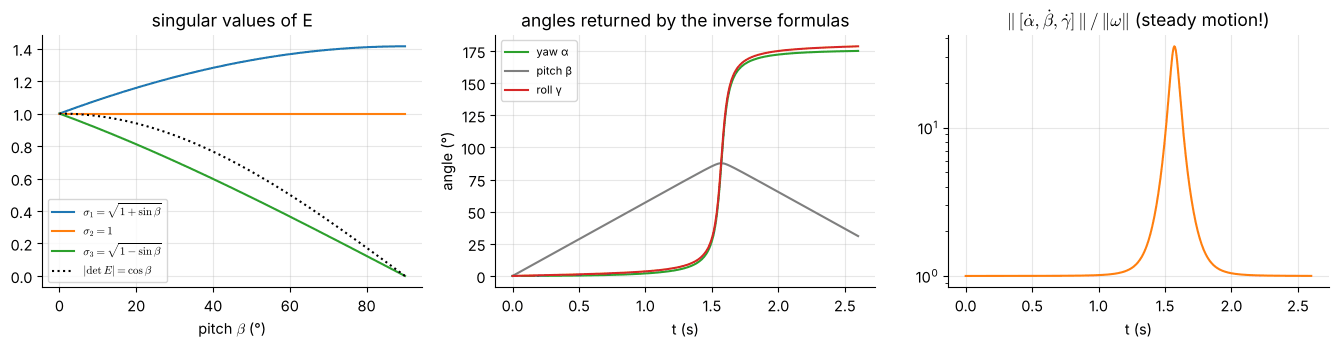

closest approach: pitch 87.71° at t = 1.57 s; the angle rates peak at 35.4 times |omega|  (1/cos(beta) = 25.0)


In [16]:
k_axis = np.array([0.04, 1.0, 0.0]); k_axis /= np.linalg.norm(k_axis)                # rotation axis, 2.3 deg from Y
t = np.linspace(0.0, 2.6, 521)                                                        # theta = 1 rad/s * t, up to 149 deg
Rt = [rot_axis_angle(k_axis, tt) for tt in t]
angles_t = np.array([np.array(rpy_from_R(R)[0])[[2, 1, 0]] for R in Rt])             # (alpha, beta, gamma) at each t
rates_t = np.array([np.linalg.solve(E_zyx(a_, b_), k_axis) for a_, b_, _ in angles_t])   # omega = 1 rad/s about k_axis

fig, axs = plt.subplots(1, 3, figsize=(13.5, 3.6))
bb = np.linspace(0, np.pi / 2, 200)
axs[0].plot(np.degrees(bb), np.sqrt(1 + np.sin(bb)), label=r"$\sigma_1=\sqrt{1+\sin\beta}$"); axs[0].plot(np.degrees(bb), np.ones_like(bb), label=r"$\sigma_2=1$")
axs[0].plot(np.degrees(bb), np.sqrt(1 - np.sin(bb)), label=r"$\sigma_3=\sqrt{1-\sin\beta}$"); axs[0].plot(np.degrees(bb), np.cos(bb), "k:", label=r"$|\det E|=\cos\beta$")
axs[0].set_xlabel(r"pitch $\beta$ (°)"); axs[0].set_title("singular values of E"); axs[0].legend(fontsize=8)
for k, (name, col) in enumerate((("yaw α", "#2ca02c"), ("pitch β", "#7f7f7f"), ("roll γ", "#d62728"))):
    axs[1].plot(t, np.degrees(angles_t[:, k]), label=name, color=col)
axs[1].set_xlabel("t (s)"); axs[1].set_ylabel("angle (°)"); axs[1].set_title("angles returned by the inverse formulas"); axs[1].legend(fontsize=8)
axs[2].semilogy(t, np.linalg.norm(rates_t, axis=1), color="#ff7f0e"); axs[2].set_xlabel("t (s)")
axs[2].set_title(r"$\|\,[\dot\alpha,\dot\beta,\dot\gamma]\,\|\,/\,\|\omega\|$ (steady motion!)")
fig.tight_layout(); plt.show()
i = np.argmax(np.linalg.norm(rates_t, axis=1))
print(f"closest approach: pitch {np.degrees(angles_t[i, 1]):.2f}° at t = {t[i]:.2f} s; the angle rates peak at {np.linalg.norm(rates_t[i]):.1f} times |omega|"
      f"  (1/cos(beta) = {1 / np.cos(angles_t[i, 1]):.1f})")

### 7.4 Gimbal lock in every convention

The argument is general. For *any* of the 24 conventions the angular velocity is a sum of three rate-times-axis
terms, so there is an $E$ matrix; its determinant is $\pm\cos b$ for the **Tait–Bryan** conventions and $\pm\sin b$ for
the **proper Euler** conventions, where $b$ is the middle angle. Hence Tait–Bryan angles are singular at
$b=\pm90^\circ$ (the first and third axes coincide), and proper Euler angles at $b=0$ and $180^\circ$ (the first and
third axes coincide, or are opposite). The code builds $E$ for any convention and verifies the statement for all 24.

In [17]:
def euler_rate_matrix(angles, order, frame):
    """E with omega_world = E @ (angle rates in the order the rotations are performed)."""
    a, b, c = angles
    i, j, k = (UNIT[ch] for ch in order)
    ri, rj, rk = (ELEM[ch] for ch in order)
    if frame == "current":                         # R = Ri(a) Rj(b) Rk(c)
        return np.column_stack([i, ri(a) @ j, ri(a) @ rj(b) @ k])
    return np.column_stack([rk(c) @ rj(b) @ i, rk(c) @ j, k])      # fixed: R = Rk(c) Rj(b) Ri(a)

rng = np.random.default_rng(11)
ok_det = ok_fd = True
for seq, frame in conventions:
    ang = rng.uniform(-np.pi, np.pi, 3); rt = rng.uniform(-1, 1, 3)
    E = euler_rate_matrix(ang, seq, frame)
    mid = np.sin(ang[1]) if len(set(seq)) == 2 else np.cos(ang[1])
    ok_det &= bool(np.isclose(abs(np.linalg.det(E)), abs(mid)))
    Rf = lambda s: euler_to_rot(ang + s * rt, seq, frame)
    w = unskew((Rf(1e-6) - Rf(-1e-6)) / 2e-6 @ Rf(0).T)
    ok_fd &= bool(np.allclose(w, E @ rt, atol=1e-6))
print("|det E| = |cos b| (Tait–Bryan) or |sin b| (proper Euler) for all 24 conventions:", ok_det)
print("E @ rates equals the angular velocity from finite differences, all 24 conventions:", ok_fd)

|det E| = |cos b| (Tait–Bryan) or |sin b| (proper Euler) for all 24 conventions: True
E @ rates equals the angular velocity from finite differences, all 24 conventions: True


### Interactive exploration

Pick a convention and three angles. The panel reports the smallest singular value of $E$ — a measure of the distance from gimbal lock, equal to $\sqrt{1-\lvert\sin b\rvert}$ or
$\sqrt{1-\lvert\cos b\rvert}$ — and warns when the representation is nearly singular. Try X-Y-Z fixed with pitch $85^\circ$, then $90^\circ$,
then move the roll and the yaw slider together.

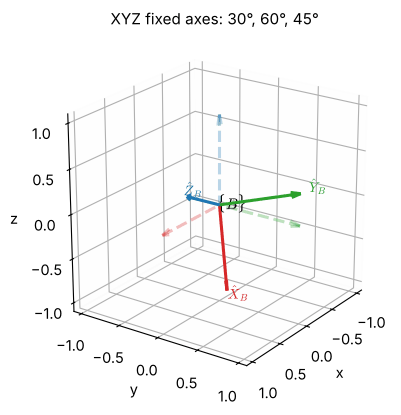

singular values of E: [1.366 1.    0.366]   smallest = 0.366  ->  well conditioned
principal angles recovered by euler_from_R (deg): [30. 60. 45.]


In [18]:
def explore_convention(order="xyz", frame="fixed", a1=30.0, a2=60.0, a3=45.0):
    ang = deg(np.array([a1, a2, a3]))
    R = euler_to_rot(ang, order, frame)
    s = np.linalg.svd(euler_rate_matrix(ang, order, frame), compute_uv=False)
    ax = new_axes3d(lim=1.1, title=f"{order.upper()} {frame} axes: {a1:.0f}°, {a2:.0f}°, {a3:.0f}°", figsize=(4.6, 4.6))
    draw_frame(ax, np.eye(3), name="A", alpha=0.3, ls="--", label_axes=False)
    draw_frame(ax, R, name="B", length=0.9)
    plt.show()
    print(f"singular values of E: {s.round(3)}   smallest = {s[-1]:.3f}  ->  " + ("NEAR GIMBAL LOCK" if s[-1] < 0.2 else "well conditioned"))
    print("principal angles recovered by euler_from_R (deg):", np.degrees(euler_from_R(R, order, frame)).round(2))

interact(explore_convention,
         order=widgets.Dropdown(options=seqs, value="xyz", description="axes"),
         frame=widgets.ToggleButtons(options=["fixed", "current"], value="fixed"),
         a1=widgets.FloatSlider(30, min=-180, max=180, step=5, description="1st (°)"),
         a2=widgets.FloatSlider(60, min=-180, max=180, step=5, description="2nd (°)"),
         a3=widgets.FloatSlider(45, min=-180, max=180, step=5, description="3rd (°)"));

### 7.5 Consequences

* **Large angle changes for small orientation changes.** Near the singularity, a small physical rotation can demand
  large changes of two angles (Section 6, last experiment above).
* **Interpolation and control in angle space is unreliable.** Interpolating the three angles linearly between two
  nearby orientations near lock produces wild intermediate motion; Section 2.5 compares this with SLERP.
* **Real mechanisms lose a degree of freedom.** A robot wrist whose joint axes line up (the three-roll wrist at
  $\beta=0$ for a Z-Y-Z wrist) is *physically* singular; Chapter 5 shows that the manipulator Jacobian loses rank at
  the same configurations.
* **The cure** is not a cleverer set of three angles — none exists — but a redundant representation
  (rotation matrix, quaternion, Section 2.5) for computation, with angles used only at the boundaries.

## 8. A teach pendant and two real robots

A **teach pendant** is the hand-held terminal with which an operator jogs an industrial robot and records
positions. It typically displays the tool pose as $(x, y, z)$ and three orientation angles. Controllers differ in the
convention they use for these angles (Section 5), so the *same* physical pose is displayed with *different*
numbers on different robots. We reproduce the display for two real manipulators from MuJoCo Menagerie
([`docs/MUJOCO.md`](../../docs/MUJOCO.md) explains the model download): the six-joint **UR5e** and the seven-joint
**Franka Emika Panda**. For each joint configuration we read the orientation of the tool frame in the world frame —
`data.site_xmat` for the UR5e's `attachment_site` (the flange), `data.xmat` of the `hand` body for the Panda, which
has no site — convert it to X-Y-Z fixed angles (roll–pitch–yaw) and Z-Y-Z angles with the functions of Section 6, and
verify that rebuilding the matrix from the angles recovers MuJoCo's matrix. These are the angles of the *simulator's
world frame*, not the display of any particular controller.

| robot | configuration (joint angles, °) | tool position (m) | roll, pitch, yaw (°) | Z-Y-Z: α, β, γ (°) | rebuild error |
|:--|:--|:--|:--|:--|--:|
| UR5e | home: [-90, -90, 90, -90, -90, 0] | (-0.134, +0.492, +0.488) | (+180.0, +0.0, -0.0) | (+0.0, +180.0, +180.0) | 7e-16 |
| UR5e | A: [-60, -110, 100, -80, -70, 25] | (-0.316, +0.211, +0.536) | (+171.3, +18.1, +3.6) | (-150.0, +160.0, +25.0) | 7e-16 |
| UR5e | B: [30, -70, 80, -100, -45, 60] | (-0.444, -0.493, +0.424) | (+139.1, +20.7, +52.2) | (-60.0, +135.0, +60.0) | 3e-16 |
| UR5e | wrist straight: [-90, -90, 90, -90, 0, 0] | (-0.234, +0.492, +0.588) | (+180.0, +90.0, +0.0) | (+180.0, +90.0, +0.0) | 8e-16 |
| Panda | home: [0, 0, 0, -90, 0, 90, -45] | (+0.554, +0.000, +0.625) | (+180.0, -0.0, +90.0) | (+0.0, +180.0, +90.0) | 9e-16 |
| Panda | A: [30, -20, 10, -100, 20, 110, -45] | (+0.327, +0.333, +0.757) | (+149.9, -16.3, +132.9) | (+68.7, +146.1, +120.2) | 7e-16 |
| Panda | B: [-40, 30, 0, -80, -30, 60, 45] | (+0.415, -0.438, +0.393) | (+138.6, +44.7, -60.6) | (+170.8, +122.3, +33.8) | 9e-16 |

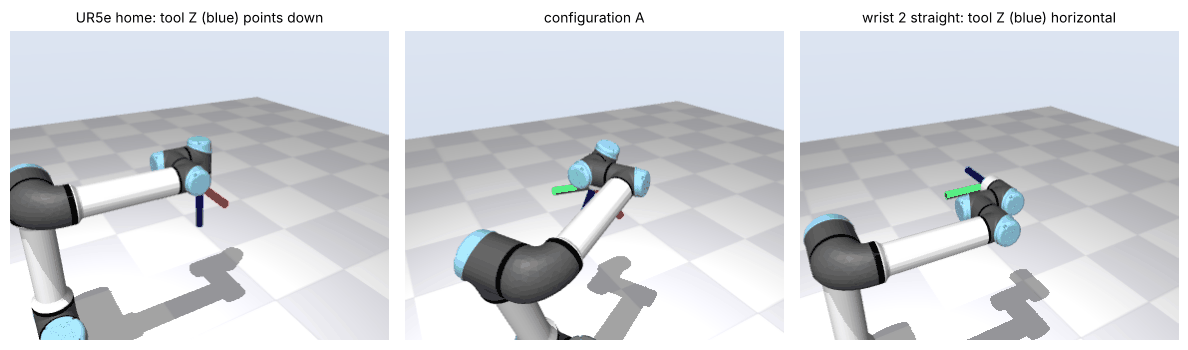

Universal Robots UR5e — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/universal_robots_ur5e) (Universal Robots; licence: BSD-3-Clause)
Franka Emika Panda — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/franka_emika_panda) (Franka Emika; licence: Apache-2.0)


In [19]:
from rgkit import robots
ur5e, ur5e_d = robots.load_robot("ur5e")
panda, panda_d = robots.load_robot("panda")

def ur5e_tool(q_deg):
    ur5e_d.qpos[:6] = np.radians(q_deg); mujoco.mj_forward(ur5e, ur5e_d)
    s = ur5e_d.site("attachment_site"); return s.xmat.reshape(3, 3).copy(), s.xpos.copy()

def panda_tool(q_deg):
    panda_d.qpos[:7] = np.radians(q_deg); mujoco.mj_forward(panda, panda_d)
    h = panda_d.body("hand"); return h.xmat.reshape(3, 3).copy(), h.xpos.copy()

ur_cfgs = {"home": [-90, -90, 90, -90, -90, 0], "A": [-60, -110, 100, -80, -70, 25], "B": [30, -70, 80, -100, -45, 60],
           "wrist straight": [-90, -90, 90, -90, 0, 0]}
pa_cfgs = {"home": [0, 0, 0, -90, 0, 90, -45], "A": [30, -20, 10, -100, 20, 110, -45], "B": [-40, 30, 0, -80, -30, 60, 45]}

rows = ["| robot | configuration (joint angles, °) | tool position (m) | roll, pitch, yaw (°) | Z-Y-Z: α, β, γ (°) | rebuild error |", "|:--|:--|:--|:--|:--|--:|"]
for robot, cfgs, fk in (("UR5e", ur_cfgs, ur5e_tool), ("Panda", pa_cfgs, panda_tool)):
    for name, q in cfgs.items():
        R, p = fk(q)
        (g, b, a), _ = rpy_from_R(R)
        (a2, b2, g2), _ = zyz_from_R(R)
        err = max(abs(rpy_to_rot(g, b, a) - R).max(), abs(euler_zyz_to_rot(a2, b2, g2) - R).max())
        assert err < 1e-9
        rows.append(f"| {robot} | {name}: {q} | ({p[0]:+.3f}, {p[1]:+.3f}, {p[2]:+.3f}) | "
                    f"({np.degrees(g):+.1f}, {np.degrees(b):+.1f}, {np.degrees(a):+.1f}) | "
                    f"({np.degrees(a2):+.1f}, {np.degrees(b2):+.1f}, {np.degrees(g2):+.1f}) | {err:.0e} |")
display(Markdown("\n".join(rows)))

opt = robots.frames_option(ur5e, length=0.15, width=0.012, kind="site")     # draw the frame of the tool site ...
opt.sitegroup[:] = 1                                                      # ... which the UR5e model puts in site group 4
shots = []
for name in ("home", "A", "wrist straight"):
    _, p_tool = ur5e_tool(ur_cfgs[name])
    shots.append(mju.render(ur5e, ur5e_d, camera=dict(azimuth=150, elevation=-25, distance=1.2, lookat=tuple(p_tool)),
                            width=380, height=310, scene_option=opt))
filmstrip(shots, ["UR5e home: tool Z (blue) points down", "configuration A", "wrist 2 straight: tool Z (blue) horizontal"])
print(robots.describe("ur5e")); print(robots.describe("panda"))

Several features of the table repay study.

* **Home pose.** The UR5e's tool points straight down, so its matrix is $R_X(180^\circ)$: roll $\pm180^\circ$, pitch
  $0$, yaw $0$. The sign of the roll is *numerically ambiguous* — $+180^\circ$ and $-180^\circ$ are the same angle
  — and rounding noise of order $10^{-16}$ in $r_{32}$ decides which one is printed. Pendants therefore never
  treat a roll near $\pm180^\circ$ as a discontinuity of the motion.
* **Z-Y-Z and a tool pointing down.** A downward-pointing tool has $\beta = 180^\circ$ in the Z-Y-Z convention, which
  is a *singular* configuration of that convention (Section 6): the pick-and-place pose that robots use most is a
  gimbal lock of Z-Y-Z. This is why Z-Y-Z is good for describing a *wrist* but is rarely shown on a pendant.
* **Wrist straight.** With wrist-2 at $0$ the tool axis is horizontal and the X-Y-Z pitch is exactly $90^\circ$: the
  roll and the yaw are not individually defined, and the table shows the convention $\mathrm{yaw}=0$. The next
  cell jogs wrist 2 through this configuration.

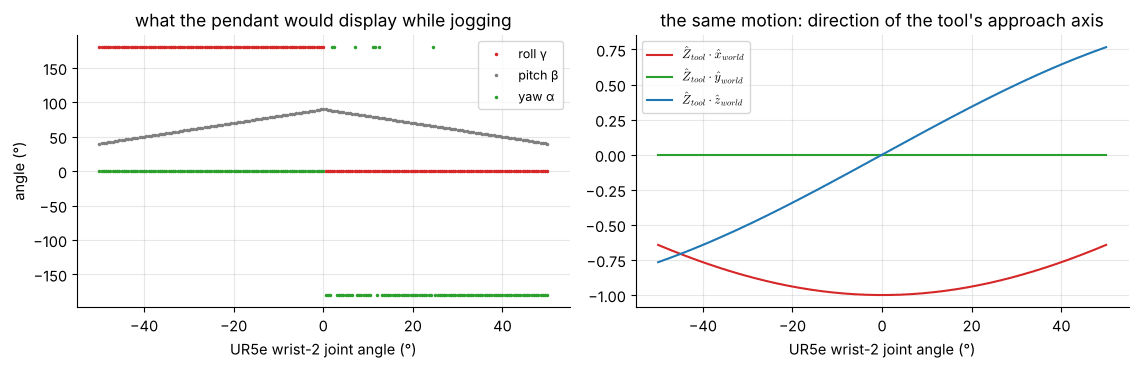

joint angle 0.0°: pitch = 90.0°.  Five samples before / after: (roll, pitch, yaw) =  [180.   87.5   0. ] / [  0.   87.5 180. ]


In [20]:
q_sweep = np.radians(np.linspace(-50, 50, 201))
sweep, tool_z = [], []
for q5 in q_sweep:
    q = np.radians(ur_cfgs["home"]).copy(); q[4] = q5
    ur5e_d.qpos[:6] = q; mujoco.mj_forward(ur5e, ur5e_d)
    R = ur5e_d.site("attachment_site").xmat.reshape(3, 3).copy()
    (g, b, a), _ = rpy_from_R(R, tol=1e-6)
    sweep.append([g, b, a]); tool_z.append(R[:, 2])
sweep, tool_z = np.degrees(np.array(sweep)), np.array(tool_z)

fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.8), sharex=True)
for k, (name, col) in enumerate((("roll γ", "#d62728"), ("pitch β", "#7f7f7f"), ("yaw α", "#2ca02c"))):
    axs[0].plot(np.degrees(q_sweep), sweep[:, k], ".", ms=3, color=col, label=name)
axs[0].set_xlabel("UR5e wrist-2 joint angle (°)"); axs[0].set_ylabel("angle (°)")
axs[0].set_title("what the pendant would display while jogging"); axs[0].legend(fontsize=9)
for k, (name, col) in enumerate((("x", AXIS_COLORS["x"]), ("y", AXIS_COLORS["y"]), ("z", AXIS_COLORS["z"]))):
    axs[1].plot(np.degrees(q_sweep), tool_z[:, k], color=col, label=rf"$\hat Z_{{tool}}\cdot\hat {name}_{{world}}$")
axs[1].set_xlabel("UR5e wrist-2 joint angle (°)"); axs[1].set_title("the same motion: direction of the tool's approach axis"); axs[1].legend(fontsize=9)
fig.tight_layout(); plt.show()
j = np.argmin(abs(q_sweep))
print(f"joint angle {np.degrees(q_sweep[j]):.1f}°: pitch = {sweep[j, 1]:.1f}°.  Five samples before / after: (roll, pitch, yaw) = ",
      sweep[j - 5].round(1), "/", sweep[j + 5].round(1))

The pitch rises to $90^\circ$ and falls again, which is a perfectly smooth motion of the tool, yet the roll and the
yaw each jump by $180^\circ$ when the joint passes through $0$. The pendant's three numbers are discontinuous while
the physical motion is not.

### Feeding MuJoCo with the displayed angles

Finally, close the loop through the simulator. Place a free-standing body whose orientation is *specified* by the
roll–pitch–yaw of the UR5e tool, using MJCF's `euler` attribute: with `eulerseq="XYZ"` (upper case: fixed axes, listed
in the order performed) the angles $(\gamma,\beta,\alpha)$ are exactly roll, pitch, yaw; with `eulerseq="zyx"` (lower
case: moving axes) the angles $(\alpha,\beta,\gamma)$ are the Z-Y-X Euler angles of the same matrix. MuJoCo must then
reproduce the matrix it reported for the tool.

In [21]:
R_tool, _ = ur5e_tool(ur_cfgs["A"])
(g, b, a), alt = rpy_from_R(R_tool)

def mujoco_orientation(seq, angles):
    xml = (f'<mujoco><compiler angle="radian" eulerseq="{seq}"/><worldbody>'
           f'<body name="b" euler="{angles[0]} {angles[1]} {angles[2]}"/></worldbody></mujoco>')
    m = mujoco.MjModel.from_xml_string(xml); d = mujoco.MjData(m); mujoco.mj_forward(m, d)
    return d.body("b").xmat.reshape(3, 3)

print("UR5e configuration A: (roll, pitch, yaw) =", np.degrees([g, b, a]).round(2), "deg;  alternate solution =", np.degrees(alt).round(2), "deg")
print("eulerseq='XYZ' with (roll, pitch, yaw) reproduces the tool matrix:       ", np.allclose(mujoco_orientation("XYZ", (g, b, a)), R_tool))
print("eulerseq='xyz' with the same numbers does NOT (moving axes, wrong order):", not np.allclose(mujoco_orientation("xyz", (g, b, a)), R_tool))
print("eulerseq='zyx' with (yaw, pitch, roll) reproduces it (Z-Y-X Euler angles):", np.allclose(mujoco_orientation("zyx", (a, b, g)), R_tool))
print("the alternate (second) solution describes the same orientation too:        ", np.allclose(mujoco_orientation("XYZ", alt), R_tool))

UR5e configuration A: (roll, pitch, yaw) = [171.26  18.06   3.61] deg;  alternate solution = [  -8.74  161.94 -176.39] deg
eulerseq='XYZ' with (roll, pitch, yaw) reproduces the tool matrix:        True
eulerseq='xyz' with the same numbers does NOT (moving axes, wrong order): True
eulerseq='zyx' with (yaw, pitch, roll) reproduces it (Z-Y-X Euler angles): True
the alternate (second) solution describes the same orientation too:         True


## 9. Worked examples

**Example 2.4.1 — roll, pitch and yaw to a matrix.** A camera is rolled $20^\circ$, pitched $-35^\circ$ and yawed
$110^\circ$ (X-Y-Z fixed angles). Find ${}^{A}_{B}R$ and the direction of its optical axis $\hat Z_B$.

*Solution.* With $c_\beta = \cos(-35^\circ) = 0.8192$, $s_\beta = -0.5736$, $c_\alpha = \cos110^\circ = -0.3420$,
$s_\alpha = 0.9397$, $c_\gamma = 0.9397$ and $s_\gamma = 0.3420$, the entries of Section 2 give
$r_{11} = c_\alpha c_\beta = -0.2802$, $r_{21} = s_\alpha c_\beta = 0.7698$, $r_{31} = -s_\beta = 0.5736$,
$r_{32} = c_\beta s_\gamma = 0.2802$ and $r_{33} = c_\beta c_\gamma = 0.7698$. The optical axis is the third
column, $\hat Z_B = (0.5057,\ -0.3895,\ 0.7698)$.

**Example 2.4.2 — the inverse problem.** Find the X-Y-Z fixed angles of
$$R = \begin{bmatrix}-0.1574 & 0.8896 & -0.4288\\ 0.8925 & -0.0577 & -0.4473\\ -0.4226 & -0.4532 & -0.7849\end{bmatrix}.$$

*Solution.* $c_\beta = \sqrt{r_{11}^2+r_{21}^2} = \sqrt{0.1574^2+0.8925^2} = 0.9063$, so
$\beta = \operatorname{atan2}(0.4226,\ 0.9063) = 25.0^\circ$. Then $\alpha = \operatorname{atan2}(0.8925,\ -0.1574) = 100.0^\circ$
and $\gamma = \operatorname{atan2}(-0.4532,\ -0.7849) = -150.0^\circ$. The second solution is
$(\gamma+180^\circ,\ 180^\circ-\beta,\ \alpha+180^\circ) = (30.0^\circ,\ 155.0^\circ,\ -80.0^\circ)$ (angles reduced to
$(-180^\circ,180^\circ]$), and both reproduce $R$.

**Example 2.4.3 — Z-Y-Z angles.** Find the Z-Y-Z Euler angles of
$$R = \begin{bmatrix}0.5144 & -0.4660 & 0.7198\\ -0.7950 & 0.0554 & 0.6040\\ -0.3214 & -0.8830 & -0.3420\end{bmatrix}.$$

*Solution.* $s_\beta = \sqrt{r_{31}^2+r_{32}^2} = \sqrt{0.3214^2+0.8830^2} = 0.9397$ and $r_{33} = -0.3420$, so
$\beta = \operatorname{atan2}(0.9397,\ -0.3420) = 110.0^\circ$. Then $\alpha = \operatorname{atan2}(r_{23}/s_\beta,\ r_{13}/s_\beta)
= \operatorname{atan2}(0.6040,\ 0.7198) = 40.0^\circ$ and $\gamma = \operatorname{atan2}(r_{32}/s_\beta,\ -r_{31}/s_\beta)
= \operatorname{atan2}(-0.8830,\ 0.3214) = -70.0^\circ$. The second solution is $(-140^\circ,\ -110^\circ,\ 110^\circ)$.

**Example 2.4.4 — gimbal lock.** Show that $(\gamma,\beta,\alpha) = (65^\circ, 90^\circ, 15^\circ)$ and
$(95^\circ, 90^\circ, 45^\circ)$ describe the same orientation, and report the angles the inverse formulas return.

*Solution.* Both have $\gamma-\alpha = 50^\circ$, so by Section 7.2 both give
$R = \begin{bmatrix}0&0.7660&0.6428\\0&0.6428&-0.7660\\-1&0&0\end{bmatrix}$. The inverse formulas of Section 6 return the
convention $\alpha=0$, $\gamma=\operatorname{atan2}(r_{12},r_{22}) = \operatorname{atan2}(0.7660, 0.6428) = 50.0^\circ$ for
*both* matrices — they cannot tell the two angle sets apart.

**Example 2.4.5 — changing convention.** A camera reports X-Y-Z fixed angles $(\gamma,\beta,\alpha) = (30^\circ, 20^\circ,
-50^\circ)$, but a controller expects Z-Y-Z Euler angles. Convert.

*Solution.* Build the matrix, $R = R_Z(-50^\circ)R_Y(20^\circ)R_X(30^\circ)$, and apply the Z-Y-Z inverse formulas. The result is
$(\alpha,\beta,\gamma) = (-109.36^\circ,\ 35.53^\circ,\ 53.95^\circ)$. (Converting between two angle conventions *always* goes
through the matrix.) By the equivalence theorem, the same matrix has Z-Y-X Euler angles $(-50^\circ,\ 20^\circ,\ 30^\circ)$ —
the same three numbers in reverse order.

**Example 2.4.6 — where does the tool point?** The pendant of Section 8 displays roll, pitch, yaw
$= (171.3^\circ,\ 18.1^\circ,\ 3.6^\circ)$ for the UR5e in configuration A. In which direction does the tool's approach axis
$\hat Z$ point?

*Solution.* The third column of the X-Y-Z matrix is
$(c_\alpha s_\beta c_\gamma + s_\alpha s_\gamma,\ \ s_\alpha s_\beta c_\gamma - c_\alpha s_\gamma,\ \ c_\beta c_\gamma)$; with the displayed
angles this is $(-0.30,\ -0.17,\ -0.94)$ — mostly downward, tilted slightly towards $-x$ and $-y$. The cell below verifies
all six examples (Example 2.4.6 against MuJoCo).

In [22]:
# Example 2.4.1
R = rpy_to_rot(deg(20), deg(-35), deg(110))
assert np.allclose([R[0, 0], R[1, 0], R[2, 0], R[2, 1], R[2, 2]], [-0.2802, 0.7698, 0.5736, 0.2802, 0.7698], atol=5e-5)
assert np.allclose(R[:, 2], [0.5057, -0.3895, 0.7698], atol=5e-5)
print("Ex 2.4.1  R =\n", R.round(4))
# Example 2.4.2
R = np.array([[-0.1574, 0.8896, -0.4288], [0.8925, -0.0577, -0.4473], [-0.4226, -0.4532, -0.7849]])
(g, b, a), alt = rpy_from_R(R)
assert np.allclose(np.degrees([g, b, a]), [-150, 25, 100], atol=0.02) and np.allclose(np.degrees(alt), [30, 155, -80], atol=0.02)
assert np.allclose(rpy_to_rot(*alt), R, atol=2e-4)
print("Ex 2.4.2  principal (roll, pitch, yaw) =", np.degrees([g, b, a]).round(2), " alternate =", np.degrees(alt).round(2))
# Example 2.4.3
R = np.array([[0.5144, -0.4660, 0.7198], [-0.7950, 0.0554, 0.6040], [-0.3214, -0.8830, -0.3420]])
(a, b, g), alt = zyz_from_R(R)
assert np.allclose(np.degrees([a, b, g]), [40, 110, -70], atol=0.02) and np.allclose(np.degrees(alt), [-140, -110, 110], atol=0.02)
print("Ex 2.4.3  principal (alpha, beta, gamma) =", np.degrees([a, b, g]).round(2), " alternate =", np.degrees(alt).round(2))
# Example 2.4.4
R1, R2 = rpy_to_rot(deg(65), deg(90), deg(15)), rpy_to_rot(deg(95), deg(90), deg(45))
assert np.allclose(R1, R2) and np.allclose(R1[0], [0, 0.7660, 0.6428], atol=5e-5) and np.allclose(R1[1], [0, 0.6428, -0.7660], atol=5e-5)
print("Ex 2.4.4  both inverse solutions:", np.degrees(rpy_from_R(R1)[0]).round(2), np.degrees(rpy_from_R(R2)[0]).round(2))
# Example 2.4.5
R = rpy_to_rot(deg(30), deg(20), deg(-50))
assert np.allclose(np.degrees(zyz_from_R(R)[0]), [-109.36, 35.53, 53.95], atol=0.01)
assert np.allclose(np.degrees(rot_to_euler_zyx(R)), [-50, 20, 30], atol=1e-9)
print("Ex 2.4.5  Z-Y-Z angles =", np.degrees(zyz_from_R(R)[0]).round(2), "  Z-Y-X Euler =", np.degrees(rot_to_euler_zyx(R)).round(2))
# Example 2.4.6 (against MuJoCo)
R_mj, _ = ur5e_tool(ur_cfgs["A"])
g, b, a = np.radians([171.3, 18.1, 3.6])
z = [np.cos(a) * np.sin(b) * np.cos(g) + np.sin(a) * np.sin(g), np.sin(a) * np.sin(b) * np.cos(g) - np.cos(a) * np.sin(g), np.cos(b) * np.cos(g)]
assert np.allclose(z, [-0.30, -0.17, -0.94], atol=0.01) and np.allclose(R_mj[:, 2], z, atol=2e-3)
print("Ex 2.4.6  approach axis from the displayed angles:", np.round(z, 3), " MuJoCo:", R_mj[:, 2].round(3))

Ex 2.4.1  R =
 [[-0.2802 -0.8159  0.5057]
 [ 0.7698 -0.5057 -0.3895]
 [ 0.5736  0.2802  0.7698]]
Ex 2.4.2  principal (roll, pitch, yaw) = [-150.   25.  100.]  alternate = [ 30. 155. -80.]
Ex 2.4.3  principal (alpha, beta, gamma) = [ 40. 110. -70.]  alternate = [-140. -110.  110.]
Ex 2.4.4  both inverse solutions: [50. 90.  0.] [50. 90.  0.]
Ex 2.4.5  Z-Y-Z angles = [-109.36   35.53   53.95]   Z-Y-X Euler = [-50.  20.  30.]
Ex 2.4.6  approach axis from the displayed angles: [-0.297 -0.17  -0.94 ]  MuJoCo: [-0.296 -0.171 -0.94 ]


## 10. Summary

| Convention | Rotations performed | Matrix |
|:--|:--|:--|
| X-Y-Z **fixed** angles $(\gamma,\beta,\alpha)$ — roll, pitch, yaw | $\gamma$ about fixed $X$, $\beta$ about fixed $Y$, $\alpha$ about fixed $Z$ | $R_Z(\alpha)R_Y(\beta)R_X(\gamma)$ |
| Z-Y-X **Euler** angles $(\alpha,\beta,\gamma)$ | $\alpha$ about $Z$, $\beta$ about new $Y$, $\gamma$ about newest $X$ | $R_Z(\alpha)R_Y(\beta)R_X(\gamma)$ — *the same matrix* |
| Z-Y-Z **Euler** angles $(\alpha,\beta,\gamma)$ | $\alpha$ about $Z$, $\beta$ about new $Y$, $\gamma$ about newest $Z$ | $R_Z(\alpha)R_Y(\beta)R_Z(\gamma)$ |
| Equivalence | fixed $(a,b,c)$ with angles $(\theta_1,\theta_2,\theta_3)$ | $=$ moving $(c,b,a)$ with angles $(\theta_3,\theta_2,\theta_1)$ |
| Number of conventions | 12 axis sequences $\times$ {fixed, moving} | 24 conventions, 12 distinct families (6 Tait–Bryan, 6 proper Euler) |
| Inverse (RPY) | $\beta=\operatorname{atan2}(-r_{31},\sqrt{r_{11}^2+r_{21}^2})$, $\alpha=\operatorname{atan2}(r_{21},r_{11})$, $\gamma=\operatorname{atan2}(r_{32},r_{33})$ | second solution $(\gamma+180^\circ,180^\circ-\beta,\alpha+180^\circ)$ |
| Inverse (Z-Y-Z) | $\beta=\operatorname{atan2}(\sqrt{r_{31}^2+r_{32}^2},r_{33})$, $\alpha=\operatorname{atan2}(r_{23},r_{13})$, $\gamma=\operatorname{atan2}(r_{32},-r_{31})$ | second solution $(\alpha+180^\circ,-\beta,\gamma+180^\circ)$ |
| Gimbal lock | Tait–Bryan: middle angle $\pm90^\circ$; proper Euler: middle angle $0$ or $180^\circ$ | $\lvert\det E\rvert=\lvert\cos b\rvert$ resp. $\lvert\sin b\rvert$; rank $E=2$ |
| MuJoCo `eulerseq` | lower case = **moving** axes, upper case = **fixed** axes | SciPy uses the opposite letter-case rule |

### Common mistakes

* Quoting three angles **without the convention** (axes, fixed or moving, order). The numbers alone are meaningless.
* Multiplying in the wrong order: for fixed axes the *first* rotation is the *rightmost* factor.
* Using $\arctan(y/x)$ instead of `atan2(y, x)`, which loses the quadrant, and forgetting the **second solution**.
* Trusting $\alpha$ and $\gamma$ near $\beta=\pm90^\circ$: they are ill-conditioned, and only $\gamma\mp\alpha$ is reliable.
* Interpolating or filtering the three angles directly, and **differentiating** them to obtain angular velocity.
* Mixing up libraries: MuJoCo's lower-case `xyz` is SciPy's upper-case `XYZ`.
* Reading a pendant's roll of $\pm180^\circ$ as a jump of the motion.

## Exercises

**2.4.1** Derive the inverse formulas for Z-Y-Z Euler angles, and show that for $\beta=0$ the matrix equals $R_Z(\alpha+\gamma)$.

<details><summary>Answer</summary>

From the matrix of Section 4: $r_{33}=c_\beta$, $r_{31}=-s_\beta c_\gamma$, $r_{32}=s_\beta s_\gamma$, $r_{13}=c_\alpha s_\beta$,
$r_{23}=s_\alpha s_\beta$. For $s_\beta>0$ divide by $s_\beta$ and take `atan2`: $\beta=\operatorname{atan2}(\sqrt{r_{31}^2+r_{32}^2},r_{33})$,
$\alpha=\operatorname{atan2}(r_{23},r_{13})$, $\gamma=\operatorname{atan2}(r_{32},-r_{31})$. For $\beta=0$, $R_Y(0)=I$, so
$R=R_Z(\alpha)R_Z(\gamma)=R_Z(\alpha+\gamma)$: only the sum is defined.
</details>

**2.4.2** A tool is rotated $90^\circ$ about the fixed $X$ axis and then $90^\circ$ about the fixed $Z$ axis. Find its X-Y-Z fixed
angles, its Z-Y-X Euler angles and its Z-Y-Z Euler angles.

<details><summary>Answer</summary>

$R=R_Z(90^\circ)R_X(90^\circ)=\begin{bmatrix}0&0&1\\1&0&0\\0&1&0\end{bmatrix}$, so the X-Y-Z fixed angles are
$(\gamma,\beta,\alpha)=(90^\circ,0,90^\circ)$ and the Z-Y-X Euler angles are $(\alpha,\beta,\gamma)=(90^\circ,0,90^\circ)$ (the same
numbers in reverse order). For Z-Y-Z: $\beta=\operatorname{atan2}(\sqrt{0^2+1^2},0)=90^\circ$,
$\alpha=\operatorname{atan2}(r_{23},r_{13})=\operatorname{atan2}(0,1)=0$ and $\gamma=\operatorname{atan2}(r_{32},-r_{31})=\operatorname{atan2}(1,0)=90^\circ$,
so $(\alpha,\beta,\gamma)=(0,90^\circ,90^\circ)$.
</details>

**2.4.3** A controller manual states: "the orientation is given by $A, B, C$: rotate by $A$ about the world $Z$ axis, then by $B$ about
the world $Y$ axis, then by $C$ about the world $X$ axis." Write the rotation matrix in terms of $A,B,C$ and name the
convention in the terms of this notebook.

<details><summary>Answer</summary>

Fixed axes, so each rotation pre-multiplies: $R=R_X(C)\,R_Y(B)\,R_Z(A)$. This is **Z-Y-X fixed angles**, which is the
same matrix as the **X-Y-Z Euler angles** $(C,B,A)$ about moving axes. It is *not* the roll–pitch–yaw of Section 2.
</details>

**2.4.4** For Z-Y-Z Euler angles show that $\lvert\det E\rvert=\lvert\sin\beta\rvert$ and find the direction in which angular velocity
cannot be produced at $\beta=0$.

<details><summary>Answer</summary>

$E=[\hat Z,\ R_Z(\alpha)\hat Y,\ R_Z(\alpha)R_Y(\beta)\hat Z]$ with $R_Z(\alpha)R_Y(\beta)\hat Z=(c_\alpha s_\beta,s_\alpha s_\beta,c_\beta)$.
The determinant is $\hat Z\cdot\big(R_Z(\alpha)\hat Y\times(c_\alpha s_\beta,s_\alpha s_\beta,c_\beta)\big)=-s_\beta$, so
$\lvert\det E\rvert=\lvert\sin\beta\rvert$. At $\beta=0$ the first and third columns are both $\hat Z$; the range of $E$ is the span of
$\hat Z$ and $R_Z(\alpha)\hat Y$, and the direction $R_Z(\alpha)\hat X$ (in the horizontal plane, perpendicular to the second
column) cannot be generated.
</details>

**2.4.5** (*Programming*) Near what pitch does the condition number of $E$ for X-Y-Z fixed angles exceed 100? Express the
answer as the angular distance from $90^\circ$.

<details><summary>Answer</summary>

The singular values are $\sqrt{1\pm\lvert s_\beta\rvert}$, so $\kappa=\sqrt{(1+\lvert s_\beta\rvert)/(1-\lvert s_\beta\rvert)}>100$ when
$\lvert s_\beta\rvert>(10^4-1)/(10^4+1)=0.9998$, i.e. within about $1.15^\circ$ of $\pm90^\circ$.
</details>

**2.4.6** (*MuJoCo*) A body is declared with `euler="30 40 70"` and `angle="degree"`. How far apart (as the angle of
the relative rotation) are the orientations obtained with `eulerseq="xyz"` and `eulerseq="XYZ"`?

<details><summary>Answer</summary>

`xyz` gives $R_X(30^\circ)R_Y(40^\circ)R_Z(70^\circ)$ (moving axes) and `XYZ` gives $R_Z(70^\circ)R_Y(40^\circ)R_X(30^\circ)$ (fixed axes);
the angle of $R_1^{\mathsf T}R_2$ is computed in the verification cell (about $58.2^\circ$): the two conventions describe clearly different frames.
</details>

**2.4.7** (*Real robot*) At which UR5e wrist-2 joint angle (the other five joints at the home values of Section 8) does the tool's
roll–pitch–yaw representation become singular, and what is the tool pointing at there?

<details><summary>Answer</summary>

At wrist-2 $=0^\circ$ (the joint passes through zero while jogging from $-50^\circ$ to $+50^\circ$ in the sweep above): the tool's
$\hat X$ axis is then vertical (pitch $=90^\circ$) — the tool axis $\hat Z$ is horizontal, along $-x$ of the world — so
the roll and yaw axes coincide.
</details>

### Checking the answers by computation

The numbers claimed in the exercise answers are verified below.

In [23]:
# 2.4.2: rotate 90 deg about fixed X, then 90 deg about fixed Z
R = rotz(deg(90)) @ rotx(deg(90))
print("2.4.2 RPY (gamma, beta, alpha) deg =", np.degrees(rpy_from_R(R)[0]).round(2) + 0.0,
      " Z-Y-X Euler (alpha, beta, gamma) =", np.degrees(rot_to_euler_zyx(R)).round(2) + 0.0,
      " Z-Y-Z (alpha, beta, gamma) =", np.degrees(zyz_from_R(R)[0]).round(2) + 0.0)
assert np.allclose(np.degrees(rpy_from_R(R)[0]), [90, 0, 90]) and np.allclose(np.degrees(zyz_from_R(R)[0]), [0, 90, 90])
# 2.4.1: beta = 0 -> Rz(alpha + gamma)
assert np.allclose(euler_zyz_to_rot(0.4, 0.0, -0.9), rotz(-0.5))
# 2.4.3: manual "A, B, C" convention = X-Y-Z moving axes with angles (C, B, A)
A_, B_, C_ = 0.3, -0.8, 1.1
assert np.allclose(rotx(C_) @ roty(B_) @ rotz(A_), euler_to_rot((C_, B_, A_), "xyz", "current"))
assert np.allclose(rotx(C_) @ roty(B_) @ rotz(A_), euler_to_rot((A_, B_, C_), "zyx", "fixed"))
# 2.4.4: |det E| = |sin beta| for Z-Y-Z; left null vector at beta = 0
E0 = euler_rate_matrix(deg([40, 0, 25]), "zyz", "current")
assert np.isclose(abs(np.linalg.det(euler_rate_matrix(deg([40, 33, 25]), "zyz", "current"))), np.sin(deg(33)))
print("2.4.4 left null vector at beta = 0 (up to sign):", abs(np.linalg.svd(E0)[0][:, -1]).round(4), " R_Z(alpha) X =", rotz(deg(40))[:, 0].round(4))
# 2.4.5: condition number > 100
s_lim = (1e4 - 1) / (1e4 + 1)
print("2.4.5 kappa > 100 within", np.degrees(np.pi / 2 - np.arcsin(s_lim)).round(3), "deg of 90 deg")
assert np.isclose(np.degrees(np.pi / 2 - np.arcsin(s_lim)), 1.15, atol=0.01)
# 2.4.6: xyz versus XYZ in MuJoCo
Ra, Rb = mujoco_orientation("xyz", deg([30, 40, 70])), mujoco_orientation("XYZ", deg([30, 40, 70]))
print("2.4.6 angle between the two orientations:", np.degrees(np.arccos((np.trace(Ra.T @ Rb) - 1) / 2)).round(2), "deg")
assert np.isclose(np.degrees(np.arccos((np.trace(Ra.T @ Rb) - 1) / 2)), 58.2, atol=0.1)
# 2.4.7: UR5e wrist-2 at 0 -> tool Z axis horizontal, pitch 90 deg
R0, _ = ur5e_tool(ur_cfgs["wrist straight"])
print("2.4.7 tool Z axis:", R0[:, 2].round(3), " pitch =", np.degrees(rpy_from_R(R0, tol=1e-6)[0][1]).round(2), "deg")
assert np.allclose(R0[:, 2], [-1, 0, 0], atol=1e-9) and np.isclose(np.degrees(rpy_from_R(R0, tol=1e-6)[0][1]), 90)

2.4.2 RPY (gamma, beta, alpha) deg = [90.  0. 90.]  Z-Y-X Euler (alpha, beta, gamma) = [90.  0. 90.]  Z-Y-Z (alpha, beta, gamma) = [ 0. 90. 90.]
2.4.4 left null vector at beta = 0 (up to sign): [0.766  0.6428 0.    ]  R_Z(alpha) X = [0.766  0.6428 0.    ]
2.4.5 kappa > 100 within 1.146 deg of 90 deg
2.4.6 angle between the two orientations: 58.24 deg
2.4.7 tool Z axis: [-1.  0.  0.]  pitch = 90.0 deg


## Further reading and lectures

* Craig §2.8 and Appendix B; Lynch & Park, Appendix B; Spong et al., Ch. 2; Siciliano et al., §2.4; Corke, *RVC*, Ch. 2.
* Video: [Prof. G. C. Nandi, Lecture 8 — How to represent orientation?](https://www.youtube.com/watch?v=HmveMBMFTtU); [Prof. G. C. Nandi, Lecture 9 — Orientation description of a rigid body](https://www.youtube.com/watch?v=MCN5ST40cy8); [Prof. G. C. Nandi, Lecture 11 — Gimbal lock explained in a practical manner](https://www.youtube.com/watch?v=m50tWpx-t0I); [Prof. G. C. Nandi, Lecture 12 — Typical solution of Euler angles, type II](https://www.youtube.com/watch?v=wjaFmQKnLOA); [ThatsEngineering — Fixed and Euler angle representation](https://www.youtube.com/watch?v=uG0P9RX65Ek); [ThatsEngineering — Euler angles — worked example](https://www.youtube.com/watch?v=8FD1jgb3Df4); [Modern Robotics 3.2.1 Rotation matrices (part 2)](https://www.youtube.com/watch?v=6KIPusOv5fA).
* MuJoCo documentation: [MJCF `compiler/eulerseq`](https://mujoco.readthedocs.io/en/stable/XMLreference.html#compiler);
  SciPy: [`Rotation.from_euler`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.transform.Rotation.from_euler.html).
* Next: [2.5 Angle–Axis and Quaternions](2.5-angle-axis-and-quaternions.ipynb) — the redundant representations that have no gimbal lock.

---

[← 2.3 Homogeneous Transformations](2.3-homogeneous-transformations.ipynb) &nbsp;·&nbsp; [Chapter contents](README.md) &nbsp;·&nbsp; [2.5 Angle–Axis and Quaternions →](2.5-angle-axis-and-quaternions.ipynb)